# In-class Competition Tutorial (Advanced Feature Engineering)
Building on tutorial_adding_features.ipynb, this notebook adds new engineered features to deliver a slight improvement in performance (ROC-AUC).

First, let's review the task we will be performing (see README.ipynb for details).

**Objective**: To predict the probability of default based on customer data.

**Evaluation metric**: ROC-AUC (Area Under the Receiver Operating Characteristic Curve)

## Contents
- [1.Setup](#scrollTo=a5KcDAE8CnmB)
- [2.Loading the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [3.Visualizing and Understanding the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [4.Preprocessing and Feature Creation](#scrollTo=rsPYkguwCnmO&line=1&uniqifier=1)
- [5.Advanced Feature Engineering](#scrollTo=GcaW-7a7ctm1&line=1&uniqifier=1)
- [6.Building the Machine Learning Model](#scrollTo=FoKdK60PCnmP&line=1&uniqifier=1)
- [7.Creating prediction results](#scrollTo=tn_kdvWYCnmQ&line=2&uniqifier=1)

## 1.Setup

### 1.1 Import Libraries
Let's load basic libraries.
Other required libraries will be loaded when we explain them.
- numpy: Library for efficient numerical computation
- pandas: Library useful for data analysis
- matplotlib: Graph drawing library
- seaborn: Graph drawing library as well

In [19]:
# Loading libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.datasets import load_breast_cancer
from sklearn.tree import  DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, train_test_split
import warnings
warnings.filterwarnings('ignore')

Run the cell below to check if the path is correctly set.

In [ ]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


## 2.Loading the Data

### 2.1 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

**IMPORTANT:**<br>
**When you make modifications to preprocessing or model training, always make sure to run all cells from this cell.**

In [ ]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

Before conducting a full-scale analysis, we will first review a brief overview of the data.

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 34 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   SK_ID_CURR                  171202 non-null  int64  
 1   NAME_CONTRACT_TYPE          171202 non-null  object 
 2   CODE_GENDER                 171202 non-null  object 
 3   CNT_CHILDREN                171202 non-null  int64  
 4   AMT_INCOME_TOTAL            171202 non-null  float64
 5   AMT_CREDIT                  171202 non-null  float64
 6   AMT_ANNUITY                 171202 non-null  float64
 7   AMT_GOODS_PRICE             171202 non-null  float64
 8   NAME_INCOME_TYPE            171202 non-null  object 
 9   NAME_EDUCATION_TYPE         171202 non-null  object 
 10  NAME_FAMILY_STATUS          171202 non-null  object 
 11  NAME_HOUSING_TYPE           171202 non-null  object 
 12  REGION_POPULATION_RELATIVE  171202 non-null  float64
 13  DAYS_BIRTH    

In [ ]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61500 entries, 0 to 61499
Data columns (total 33 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   SK_ID_CURR                  61500 non-null  int64  
 1   NAME_CONTRACT_TYPE          61500 non-null  object 
 2   CODE_GENDER                 61500 non-null  object 
 3   CNT_CHILDREN                61500 non-null  int64  
 4   AMT_INCOME_TOTAL            61500 non-null  float64
 5   AMT_CREDIT                  61500 non-null  float64
 6   AMT_ANNUITY                 61500 non-null  float64
 7   AMT_GOODS_PRICE             61500 non-null  float64
 8   NAME_INCOME_TYPE            61500 non-null  object 
 9   NAME_EDUCATION_TYPE         61500 non-null  object 
 10  NAME_FAMILY_STATUS          61500 non-null  object 
 11  NAME_HOUSING_TYPE           61500 non-null  object 
 12  REGION_POPULATION_RELATIVE  61500 non-null  float64
 13  DAYS_BIRTH                  615

In [ ]:
train.describe()

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
count,171202.00000,171202.000000,1.712020e+05,1.712020e+05,171202.000000,1.712020e+05,171202.000000,171202.000000,171202.000000,171202.000000,...,171202.000000,52274.000000,1.708330e+05,116616.000000,171202.000000,148086.000000,148086.000000,148086.000000,148086.000000,171202.000000
mean,85600.50000,0.416490,1.683712e+05,5.991293e+05,27120.065953,5.380569e+05,0.020839,-16045.340504,63960.411969,-4994.982524,...,2.053726,0.501692,5.145083e-01,0.511177,-962.407773,0.006652,0.268418,0.267547,1.903644,0.080729
std,49421.90473,0.720138,1.072348e+05,4.028170e+05,14450.252689,3.685727e+05,0.013803,4363.792228,141401.513149,3525.760241,...,0.508718,0.210950,1.912729e-01,0.194778,826.277244,0.086204,0.921022,0.914532,1.872237,0.272420
min,0.00000,0.000000,2.610000e+04,4.500000e+04,1980.000000,4.500000e+04,0.000290,-25229.000000,-17912.000000,-24672.000000,...,1.000000,0.017095,8.173617e-08,0.000527,-4173.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,42800.25000,0.000000,1.125000e+05,2.700000e+05,16546.500000,2.385000e+05,0.010006,-19686.000000,-2772.000000,-7490.000000,...,2.000000,0.333353,3.920925e-01,0.370650,-1568.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,85600.50000,0.000000,1.462500e+05,5.146020e+05,24916.500000,4.500000e+05,0.018850,-15778.000000,-1215.000000,-4515.000000,...,2.000000,0.505858,5.662998e-01,0.537070,-757.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,128400.75000,1.000000,2.025000e+05,8.086500e+05,34600.500000,6.795000e+05,0.028663,-12420.000000,-288.000000,-2008.000000,...,2.000000,0.674595,6.641587e-01,0.669057,-274.000000,0.000000,0.000000,0.000000,3.000000,0.000000
max,171201.00000,14.000000,1.350000e+07,4.050000e+06,170986.500000,2.254500e+06,0.072508,-7673.000000,365243.000000,0.000000,...,3.000000,0.947649,8.549997e-01,0.896010,0.000000,4.000000,23.000000,261.000000,23.000000,1.000000


In [ ]:
test.describe()

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,61500.000000,61500.000000,6.150000e+04,6.150000e+04,61500.000000,6.150000e+04,61500.000000,61500.000000,61500.000000,61500.000000,...,61500.000000,61500.000000,18588.000000,61370.000000,41810.000000,61500.000000,52987.000000,52987.000000,52987.000000,52987.000000
mean,201951.500000,0.421171,1.695494e+05,5.956682e+05,27028.553317,5.336714e+05,0.020780,-15915.226016,60829.342553,-4945.935935,...,2.153593,2.059610,0.490984,0.503577,0.498920,-948.243122,0.006115,0.264706,0.262423,1.909506
std,17753.665115,0.732735,4.862781e+05,3.985634e+05,14168.393666,3.645604e+05,0.013790,4359.964540,138657.773191,3496.555151,...,0.921805,0.511458,0.212924,0.195737,0.200471,823.341959,0.080577,0.886867,0.611389,1.882254
min,171202.000000,0.000000,2.565000e+04,4.500000e+04,2164.500000,4.050000e+04,0.000533,-25201.000000,-16852.000000,-22442.000000,...,1.000000,1.000000,0.014691,0.000010,0.000527,-4079.000000,0.000000,0.000000,0.000000,0.000000
25%,186576.750000,0.000000,1.125000e+05,2.700000e+05,16618.500000,2.385000e+05,0.010006,-19539.000000,-2687.000000,-7408.250000,...,2.000000,2.000000,0.319509,0.373262,0.350696,-1552.000000,0.000000,0.000000,0.000000,0.000000
50%,201951.500000,0.000000,1.440000e+05,5.094000e+05,24849.000000,4.500000e+05,0.018850,-15586.500000,-1185.000000,-4458.000000,...,2.000000,2.000000,0.492894,0.556241,0.520898,-736.000000,0.000000,0.000000,0.000000,1.000000
75%,217326.250000,1.000000,2.025000e+05,8.086500e+05,34573.500000,6.795000e+05,0.028663,-12290.000000,-300.000000,-2018.000000,...,3.000000,2.000000,0.666050,0.658453,0.661024,-266.000000,0.000000,0.000000,0.000000,3.000000
max,232701.000000,19.000000,1.170000e+08,3.860019e+06,170986.500000,2.254500e+06,0.072508,-7678.000000,365243.000000,0.000000,...,20.000000,3.000000,0.939512,0.855000,0.893976,0.000000,3.000000,27.000000,8.000000,22.000000


In [ ]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [ ]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0


In [ ]:
train.head().T

,0,1,2,3,4
SK_ID_CURR,0,1,2,3,4
NAME_CONTRACT_TYPE,Cash loans,Cash loans,Cash loans,Cash loans,Cash loans
CODE_GENDER,F,F,F,F,M
CNT_CHILDREN,0,0,0,0,0
AMT_INCOME_TOTAL,112500.0,225000.0,54000.0,67500.0,157500.0
AMT_CREDIT,755190.0,585000.0,334152.0,152820.0,271066.5
AMT_ANNUITY,36328.5,16893.0,18256.5,8901.0,21546.0
AMT_GOODS_PRICE,675000.0,585000.0,270000.0,135000.0,234000.0
NAME_INCOME_TYPE,Working,Pensioner,State servant,Pensioner,Commercial associate
NAME_EDUCATION_TYPE,Higher education,Secondary / secondary special,Secondary / secondary special,Lower secondary,Secondary / secondary special


In [ ]:
test.head().T

,0,1,2,3,4
SK_ID_CURR,171202,171203,171204,171205,171206
NAME_CONTRACT_TYPE,Cash loans,Cash loans,Cash loans,Revolving loans,Cash loans
CODE_GENDER,F,F,F,F,F
CNT_CHILDREN,1,0,1,2,2
AMT_INCOME_TOTAL,144000.0,103500.0,180000.0,225000.0,144000.0
AMT_CREDIT,961146.0,296280.0,183694.5,450000.0,545040.0
AMT_ANNUITY,28233.0,16069.5,11236.5,22500.0,26640.0
AMT_GOODS_PRICE,688500.0,225000.0,139500.0,450000.0,450000.0
NAME_INCOME_TYPE,Working,Working,Commercial associate,Working,Working
NAME_EDUCATION_TYPE,Higher education,Secondary / secondary special,Secondary / secondary special,Higher education,Higher education


In [ ]:
train.sort_index()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
171197,171197,Cash loans,M,0,83250.0,404325.0,20772.0,337500.0,Working,Secondary / secondary special,...,Agriculture,NaN,0.404560,0.768808,-2341.0,0.0,0.0,1.0,0.0,0
171198,171198,Cash loans,F,0,247500.0,601470.0,29065.5,450000.0,Working,Secondary / secondary special,...,Industry: type 3,NaN,0.608542,NaN,-1688.0,0.0,0.0,1.0,5.0,0
171199,171199,Cash loans,F,2,292500.0,1237684.5,49216.5,1138500.0,State servant,Higher education,...,School,NaN,0.664305,0.758393,-515.0,0.0,0.0,0.0,1.0,0
171200,171200,Cash loans,M,0,112500.0,239850.0,25186.5,225000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.210918,0.627050,NaN,-1133.0,NaN,NaN,NaN,NaN,0


In [ ]:
test.sort_index()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0
3,171205,Revolving loans,F,2,225000.0,450000.0,22500.0,450000.0,Working,Higher education,...,2,Business Entity Type 3,NaN,0.470384,0.217629,-442.0,0.0,0.0,0.0,3.0
4,171206,Cash loans,F,2,144000.0,545040.0,26640.0,450000.0,Working,Higher education,...,3,Business Entity Type 3,0.269931,0.373133,NaN,-1333.0,0.0,0.0,0.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61495,232697,Cash loans,F,0,315000.0,1288350.0,37800.0,1125000.0,Commercial associate,Higher education,...,2,Trade: type 7,0.263678,0.018172,0.307737,-1.0,0.0,1.0,1.0,1.0
61496,232698,Cash loans,F,0,90000.0,273636.0,15408.0,247500.0,Working,Higher education,...,2,Self-employed,NaN,0.668578,0.434733,-2732.0,0.0,0.0,0.0,0.0
61497,232699,Cash loans,F,0,144000.0,291384.0,26725.5,270000.0,Commercial associate,Higher education,...,2,Business Entity Type 3,0.510226,0.574151,NaN,-615.0,0.0,0.0,1.0,0.0
61498,232700,Cash loans,F,1,193500.0,746280.0,59094.0,675000.0,State servant,Higher education,...,3,Other,0.353295,0.226714,NaN,-1610.0,0.0,0.0,1.0,3.0


In [ ]:
train.sort_values(by="SK_ID_CURR",ascending=False)

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
171201,171201,Cash loans,F,0,108000.0,161730.0,8595.0,135000.0,Working,Secondary / secondary special,...,Kindergarten,NaN,0.517986,0.382502,-220.0,0.0,0.0,0.0,1.0,0
171200,171200,Cash loans,M,0,112500.0,239850.0,25186.5,225000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.210918,0.627050,NaN,-1133.0,NaN,NaN,NaN,NaN,0
171199,171199,Cash loans,F,2,292500.0,1237684.5,49216.5,1138500.0,State servant,Higher education,...,School,NaN,0.664305,0.758393,-515.0,0.0,0.0,0.0,1.0,0
171198,171198,Cash loans,F,0,247500.0,601470.0,29065.5,450000.0,Working,Secondary / secondary special,...,Industry: type 3,NaN,0.608542,NaN,-1688.0,0.0,0.0,1.0,5.0,0
171197,171197,Cash loans,M,0,83250.0,404325.0,20772.0,337500.0,Working,Secondary / secondary special,...,Agriculture,NaN,0.404560,0.768808,-2341.0,0.0,0.0,1.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0


In [ ]:
test.sort_values(by="SK_ID_CURR",ascending=False)

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
61499,232701,Cash loans,M,0,135000.0,568800.0,16429.5,450000.0,Working,Secondary / secondary special,...,2,Business Entity Type 3,NaN,0.270204,0.399676,-421.0,0.0,0.0,0.0,0.0
61498,232700,Cash loans,F,1,193500.0,746280.0,59094.0,675000.0,State servant,Higher education,...,3,Other,0.353295,0.226714,NaN,-1610.0,0.0,0.0,1.0,3.0
61497,232699,Cash loans,F,0,144000.0,291384.0,26725.5,270000.0,Commercial associate,Higher education,...,2,Business Entity Type 3,0.510226,0.574151,NaN,-615.0,0.0,0.0,1.0,0.0
61496,232698,Cash loans,F,0,90000.0,273636.0,15408.0,247500.0,Working,Higher education,...,2,Self-employed,NaN,0.668578,0.434733,-2732.0,0.0,0.0,0.0,0.0
61495,232697,Cash loans,F,0,315000.0,1288350.0,37800.0,1125000.0,Commercial associate,Higher education,...,2,Trade: type 7,0.263678,0.018172,0.307737,-1.0,0.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4,171206,Cash loans,F,2,144000.0,545040.0,26640.0,450000.0,Working,Higher education,...,3,Business Entity Type 3,0.269931,0.373133,NaN,-1333.0,0.0,0.0,0.0,3.0
3,171205,Revolving loans,F,2,225000.0,450000.0,22500.0,450000.0,Working,Higher education,...,2,Business Entity Type 3,NaN,0.470384,0.217629,-442.0,0.0,0.0,0.0,3.0
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN


Excluding the `TARGET` column in train data and the `SK_ID_CURR` which represents ID number, you can see that there are 32 types of features.

###This time, we'll review all candidate features and use the majority in our model.

## 3.Visualizing and Understanding the Data

The first thing we need to do before building the machine learning model is to **understand the data**. We do this by visualizing and analyzing, to deepen our understanding of data distribution, missing values, outliers, correlations, and etc. The results of the analysis obtained at this stage will be useful for preprocessing, feature creation, and selection of machine learning models, which are all important to building models with better prediction ability.

### 3.1 Checking missing values
In this section, we check for missing values.
This is important as **most machine learning models cannot be trained on data with missing values**. If there are missing values, they need to be filled with some value.

In [ ]:
# Check missing values of train data
train.isnull().sum()

,0
SK_ID_CURR,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0


In [ ]:
# Check missing values of test data
test.isnull().sum()

,0
SK_ID_CURR,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0


In [ ]:
train.dropna()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
28,28,Cash loans,M,1,360000.0,1325475.0,59256.0,1125000.0,Working,Secondary / secondary special,...,Self-employed,0.857783,0.383423,0.207964,-2607.0,0.0,0.0,1.0,1.0,1
35,35,Cash loans,F,0,162000.0,1129500.0,47983.5,1129500.0,Working,Secondary / secondary special,...,Business Entity Type 3,0.303471,0.762308,0.434733,-936.0,0.0,0.0,0.0,1.0,0
47,47,Cash loans,F,2,270000.0,487971.0,47668.5,463500.0,Working,Higher education,...,Business Entity Type 3,0.644169,0.603890,0.607557,-432.0,0.0,0.0,0.0,2.0,0
48,48,Cash loans,F,0,157500.0,1208304.0,51192.0,1080000.0,Pensioner,Secondary / secondary special,...,XNA,0.335767,0.432641,0.735221,-462.0,0.0,0.0,0.0,2.0,0
49,49,Cash loans,M,0,135000.0,467257.5,16911.0,328500.0,State servant,Secondary / secondary special,...,Other,0.180120,0.538859,0.542445,-594.0,0.0,0.0,2.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
171137,171137,Cash loans,F,1,135000.0,225000.0,7065.0,225000.0,Commercial associate,Higher education,...,Bank,0.622534,0.335620,0.368969,-635.0,0.0,0.0,0.0,1.0,0
171146,171146,Cash loans,F,0,108000.0,206271.0,20223.0,193500.0,Commercial associate,Higher education,...,Other,0.589242,0.431144,0.657784,-1829.0,0.0,2.0,0.0,1.0,0
171165,171165,Cash loans,M,2,225000.0,874152.0,46701.0,810000.0,Working,Secondary / secondary special,...,Housing,0.242356,0.481554,0.879506,-1361.0,0.0,1.0,0.0,3.0,0
171166,171166,Cash loans,F,1,225000.0,1078200.0,31653.0,900000.0,Working,Higher education,...,Other,0.644282,0.625443,0.362277,-667.0,0.0,0.0,1.0,1.0,0


In [ ]:
test.dropna()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
9,171211,Cash loans,F,0,180000.0,431280.0,22149.0,360000.0,Commercial associate,Secondary / secondary special,...,2,Business Entity Type 3,0.389262,0.555237,0.336062,-2729.0,0.0,0.0,1.0,7.0
12,171214,Cash loans,M,0,157500.0,450000.0,22018.5,450000.0,Working,Secondary / secondary special,...,2,Business Entity Type 3,0.236489,0.571218,0.440058,-181.0,0.0,0.0,0.0,1.0
18,171220,Cash loans,M,0,90000.0,568800.0,21573.0,450000.0,Pensioner,Higher education,...,2,XNA,0.789418,0.366137,0.517297,-782.0,0.0,0.0,1.0,3.0
40,171242,Cash loans,M,0,292500.0,193572.0,19273.5,171000.0,Pensioner,Higher education,...,1,XNA,0.735319,0.750615,0.746300,-2374.0,0.0,0.0,1.0,0.0
45,171247,Cash loans,M,1,144000.0,521280.0,28408.5,450000.0,Working,Secondary / secondary special,...,2,Transport: type 2,0.189134,0.160405,0.431192,-311.0,0.0,0.0,0.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61458,232660,Cash loans,M,1,135000.0,1282500.0,41503.5,1282500.0,Commercial associate,Higher education,...,3,Industry: type 11,0.506583,0.582969,0.657784,-1817.0,0.0,1.0,0.0,2.0
61466,232668,Cash loans,F,1,184500.0,545040.0,25537.5,450000.0,Working,Secondary / secondary special,...,2,Medicine,0.515681,0.685346,0.501075,-221.0,0.0,0.0,0.0,3.0
61476,232678,Cash loans,M,0,90000.0,143910.0,15628.5,135000.0,Working,Secondary / secondary special,...,3,Transport: type 4,0.223205,0.260195,0.570917,-2332.0,0.0,0.0,0.0,3.0
61493,232695,Cash loans,M,0,360000.0,1994670.0,52749.0,1665000.0,Commercial associate,Higher education,...,1,Construction,0.633507,0.674141,0.631355,-4.0,0.0,0.0,0.0,0.0


We found that there are missing values in OWN_CAR_AGE, CNT_FAM_MEMBERS, EXT_SOURCE_\*, AMT_REQ_CREDIT_BUREAU_\*. We will deal with these missing values later.

### 3.2 Visualization and analysis of each feature
In this section, we visualize each feature and analyze to see what kind of characteristics it has.

#### TARGET column

TARGET
0    91.92708
1     8.07292
Name: proportion, dtype: float64
------------------------------


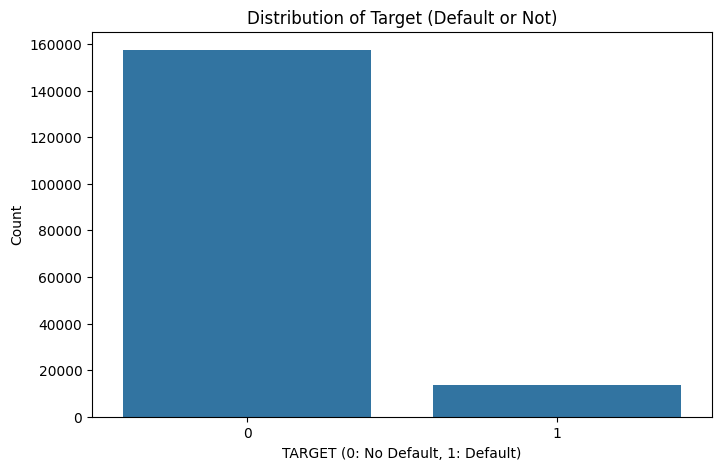

In [ ]:


distribution_pct = train["TARGET"].value_counts(normalize=True) * 100
print(distribution_pct)
print("-" * 30)


plt.figure(figsize=(8, 5))
sns.countplot(data=train, x="TARGET")


plt.title("Distribution of Target (Default or Not)")
plt.xlabel("TARGET (0: No Default, 1: Default)")
plt.ylabel("Count")


plt.show()

We can see that the **distribution of the objective variable is highly skewed**. Data in which the distribution of the objective variable is highly skewed in this way is called **unbalanced data**.

When dealing with unbalanced data, we need to be particularly careful in selecting evaluation metrics. For example, if you choose accuracy, you will find that simply predicting all zeros will result in a high accuracy. **Choosing such an inappropriate metric can cause the machine learning model to fail to predict well on new data**.

Another approach to dealing with unbalanced data is to try to balance the distribution of the target variable. The method of reducing the data of the larger target variable is called undersampling, while the method of increasing the data of the smaller objective variable is called oversampling.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable

#### NAME_CONTRACT_TYPE column

NAME_CONTRACT_TYPE
Cash loans         90.529316
Revolving loans     9.470684
Name: proportion, dtype: float64


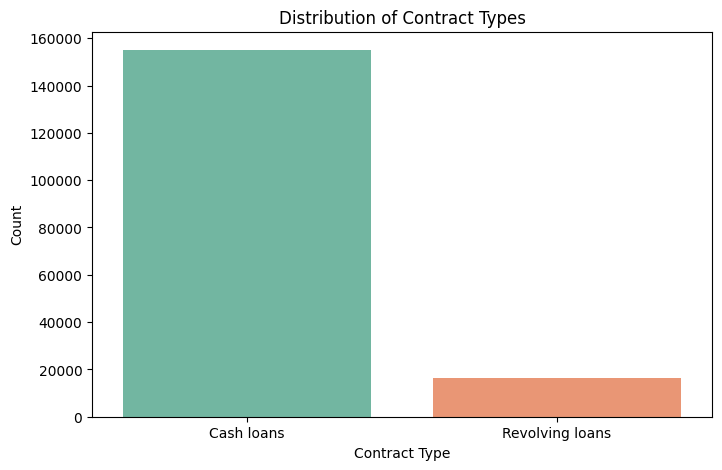

In [ ]:
print(train["NAME_CONTRACT_TYPE"].value_counts(normalize=True) * 100)

plt.figure(figsize=(8, 5))
sns.countplot(data=train, x="NAME_CONTRACT_TYPE", palette="Set2")
plt.title("Distribution of Contract Types")
plt.xlabel("Contract Type")
plt.ylabel("Count")
plt.show()

There are two variables in NAME_CONTRACT_TYPE, Cash loans and Revolving loans, but they are not evenly distributed. Also, since the machine learning model can only handle data of numeric type, it is necessary to convert the data from string type to numeric type.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable
* Need to convert the data from string type to numeric type

#### ORGANIZATION_TYPE column

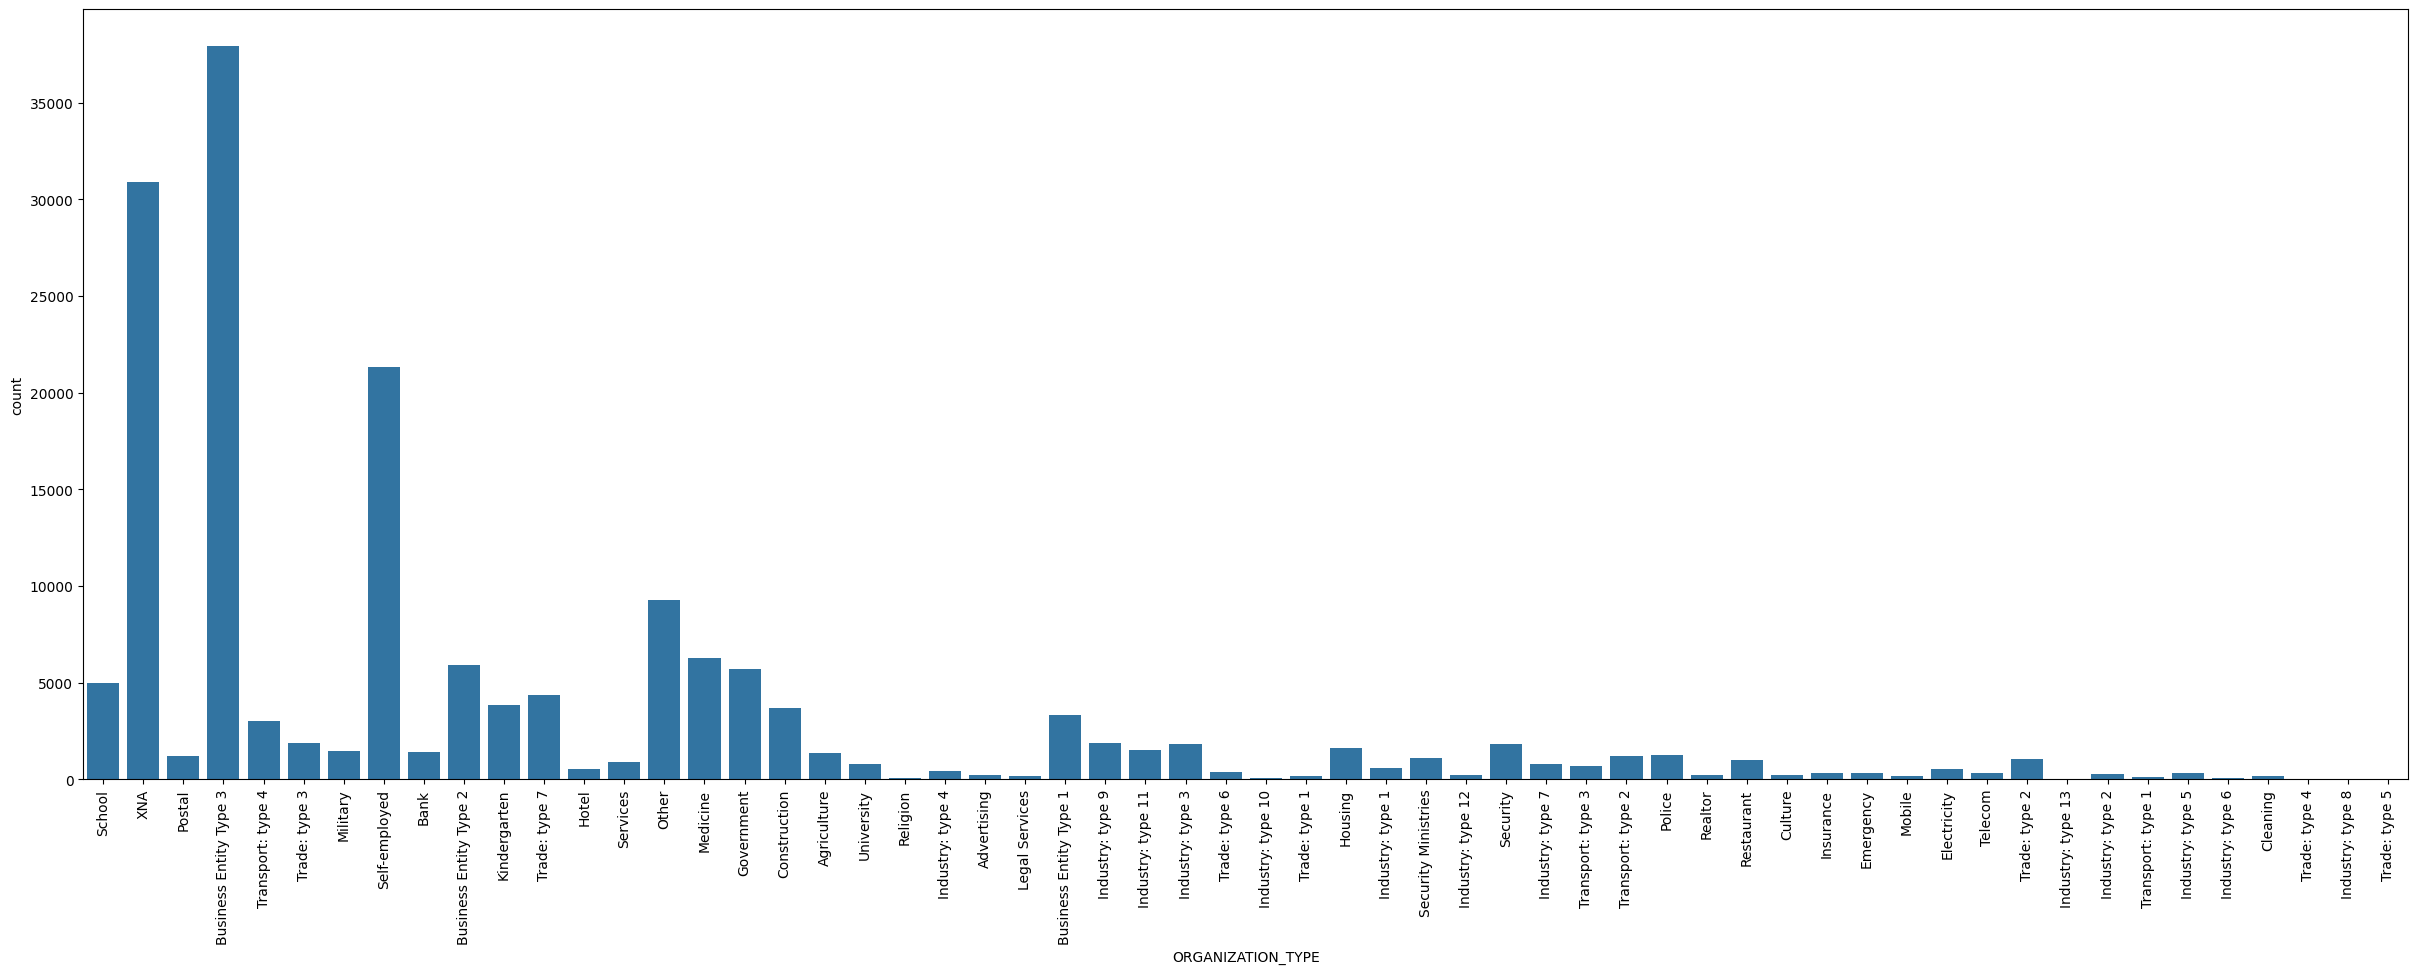

In [ ]:
# The distribution of ORGANIZATION_TYPE

plt.figure(figsize=(30, 10))

sns.countplot(data=train, x="ORGANIZATION_TYPE")

plt.tick_params(axis="x", rotation=90)

plt.show()

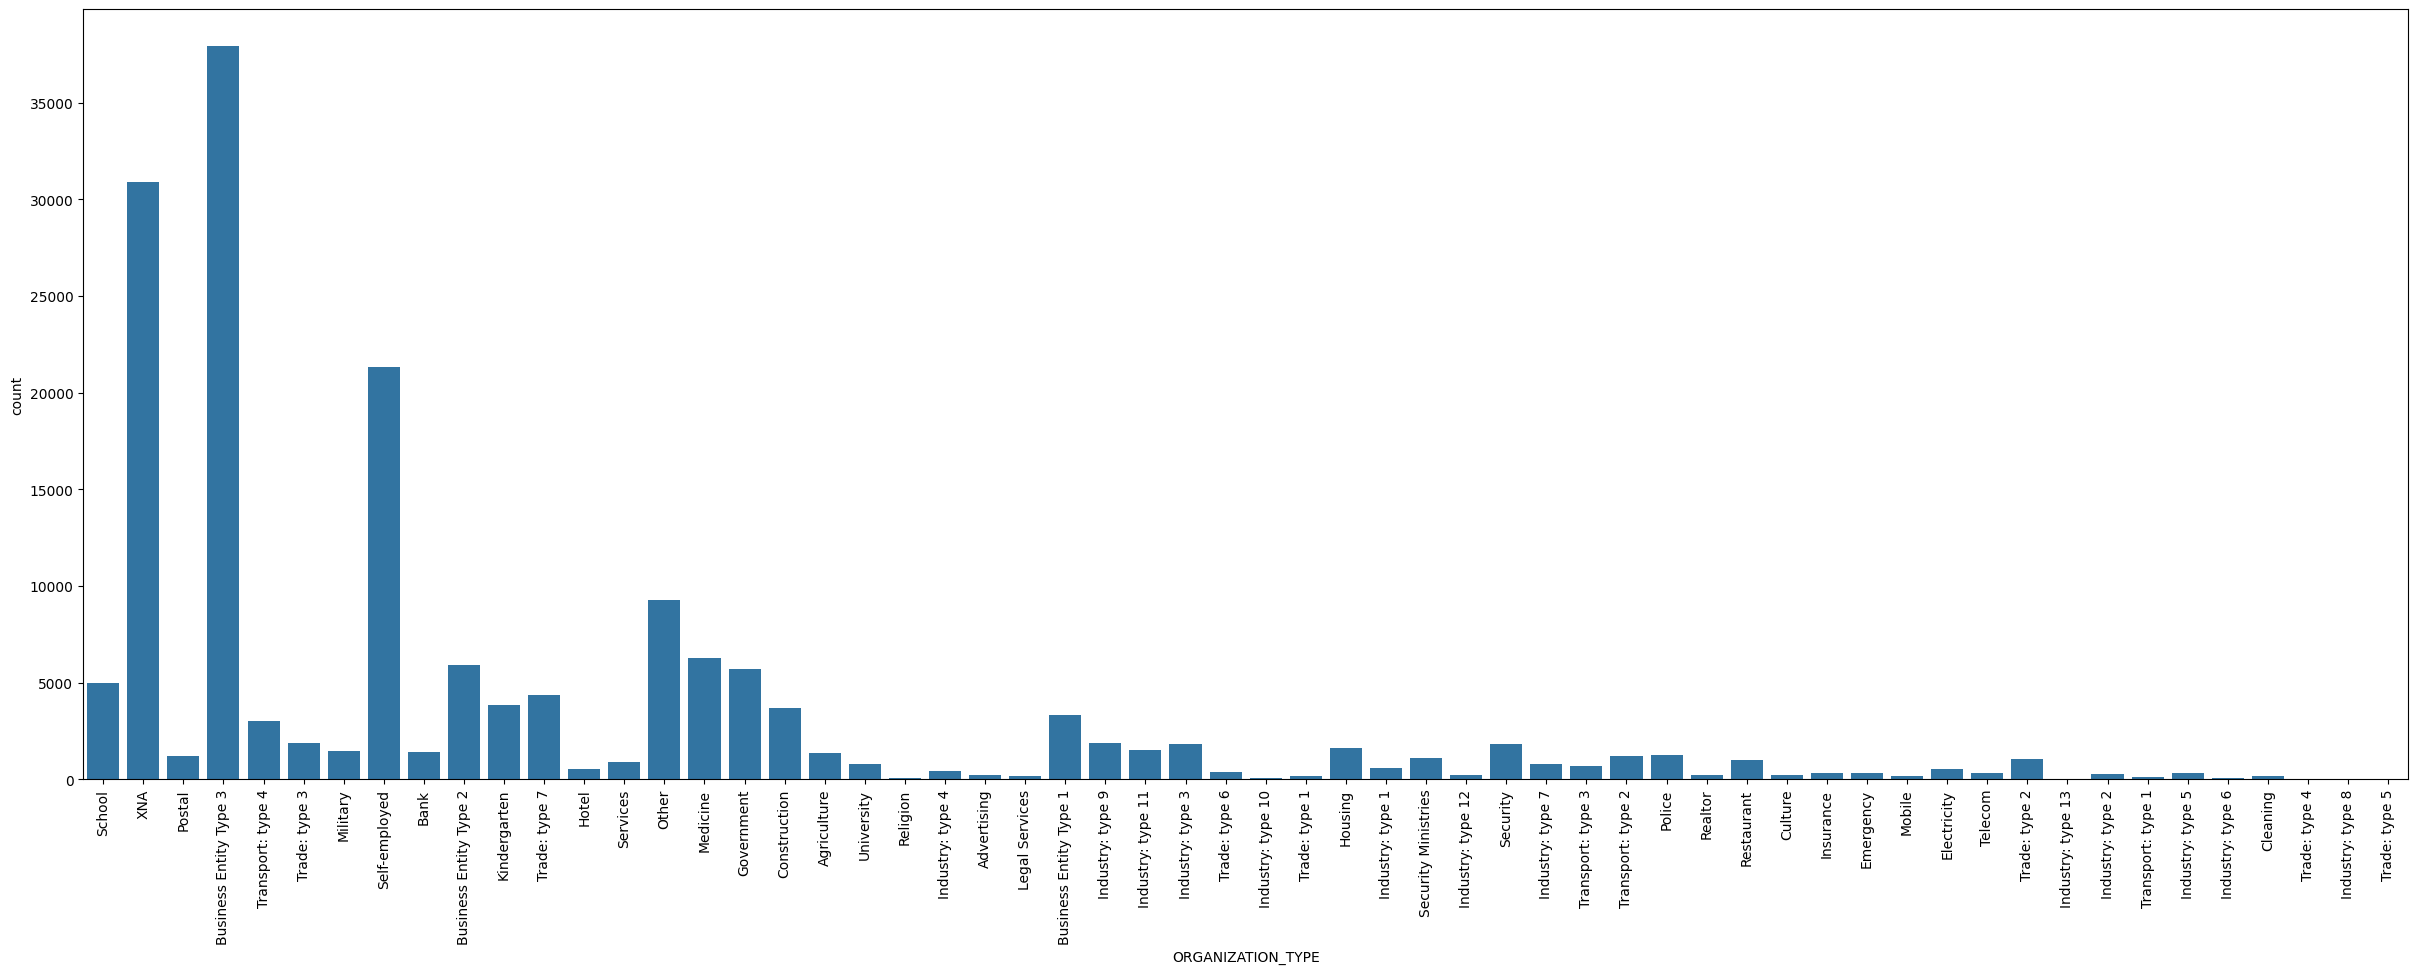

In [ ]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

There are many different ORGANIZATION_TYPEs, and you can also see that there is an ununiformity in the number of data. This is also a string type feature, so it needs to be converted to a numeric type. Also, the second variable from the left is “XNA,” which we can infer from its name to be a missing value.


**Findings**:<br>
* Treat "XNA" as missing values
* Need to convert the data from string type to numeric type

#### EXT_SOURCE_1 column

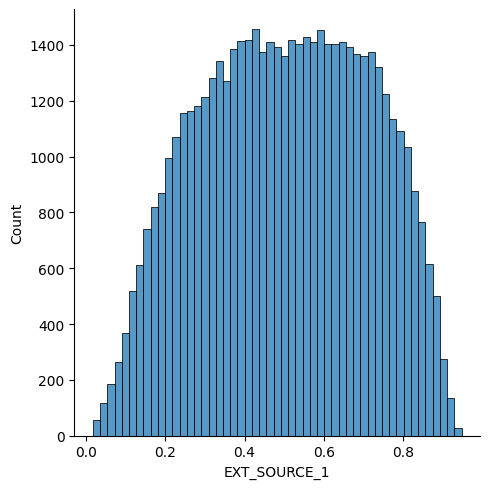

In [ ]:
# The distribution of EXT_SOURCE_1
sns.displot(data=train, x="EXT_SOURCE_1")
plt.show()

#### EXT_SOURCE_2 column

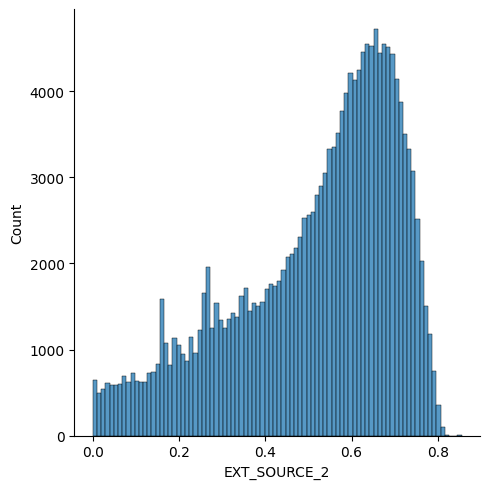

In [ ]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

#### EXT_SOURCE_3 column

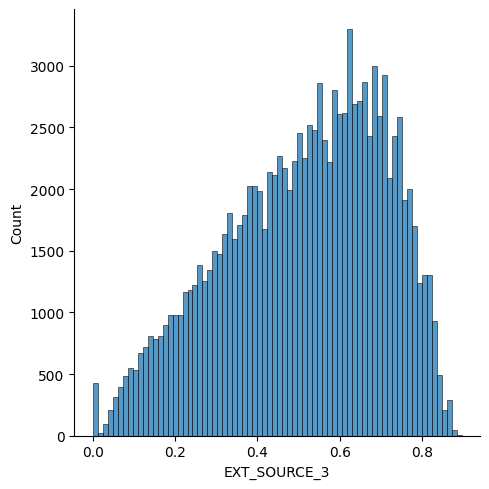

In [ ]:
# The distribution of EXT_SOURCE_3
sns.displot(data=train, x="EXT_SOURCE_3")
plt.show()

We can see that EXT_SOURCE_\* is normalized between 0 and 1. It seems we can handle this feature as it is.

**Findings**:<br>
* No additional preprocessing is needed

#### AMT_INCOME_TOTAL

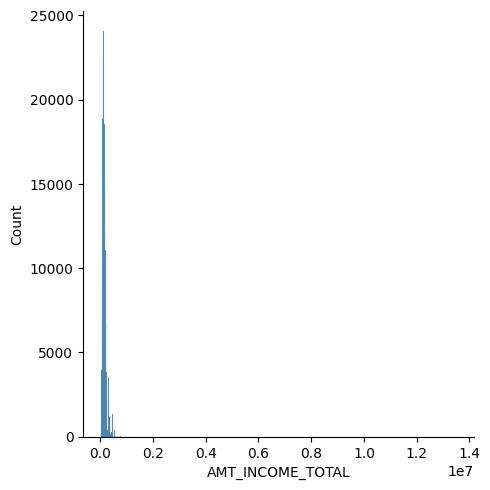

In [ ]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

The visualization of `AMT_INCOME_TOTAL` is hard to interpret because the distribution is **right-skewed** with a small number of very large outliers. To visualize data like this, a logarithmic transformation can be effective.

count    1.712020e+05
mean     1.683712e+05
std      1.072348e+05
min      2.610000e+04
25%      1.125000e+05
50%      1.462500e+05
75%      2.025000e+05
max      1.350000e+07
Name: AMT_INCOME_TOTAL, dtype: float64


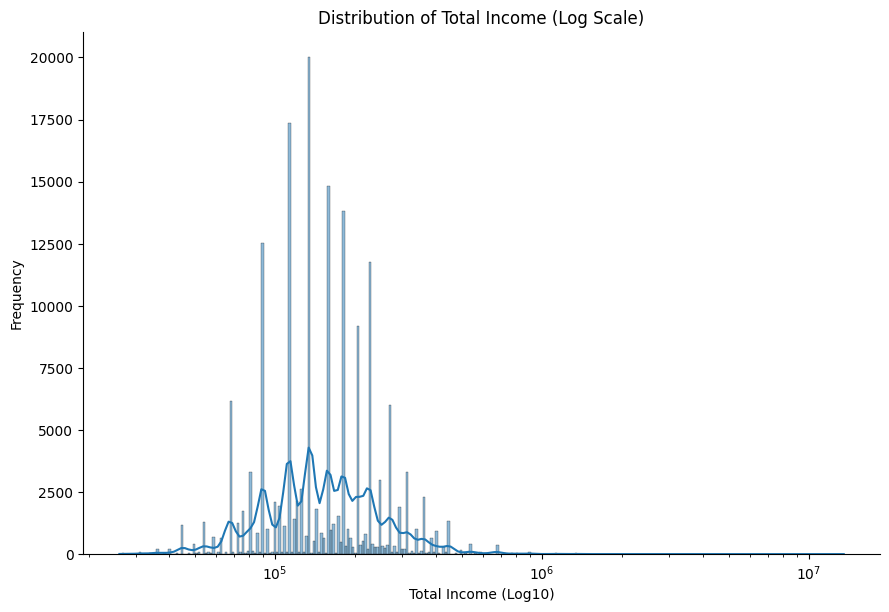

In [ ]:
print(train["AMT_INCOME_TOTAL"].describe())

g = sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10, kde=True, height=6, aspect=1.5)
g.set(title="Distribution of Total Income (Log Scale)",
      xlabel="Total Income (Log10)",
      ylabel="Frequency")

plt.show()

We displayed the graph successfully by using logarithmic transformation.
The income is supposed to be a continuous value, but it looks like a discrete value. Let's have a look at the type of `AMT_INCOME_TOTAL` values.

In [ ]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())

1641

There are 171202 data in train, but AMT_INCOME_TOTAL consists of only 1641 different values. Let's check the top 10 values specifically.

In [ ]:
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)

,count
AMT_INCOME_TOTAL,
135000.0,19969
112500.0,17320
157500.0,14772
180000.0,13791
90000.0,12481
225000.0,11573
202500.0,9128
67500.0,6130
270000.0,6006


It appears that `AMT_INCOME_TOTAL` is not an exact annual income, but rather data compiled from a rounded number.

**Findings**:<br>
* Should the outlier in the data be addressed?

#### OWN_CAR_AGE

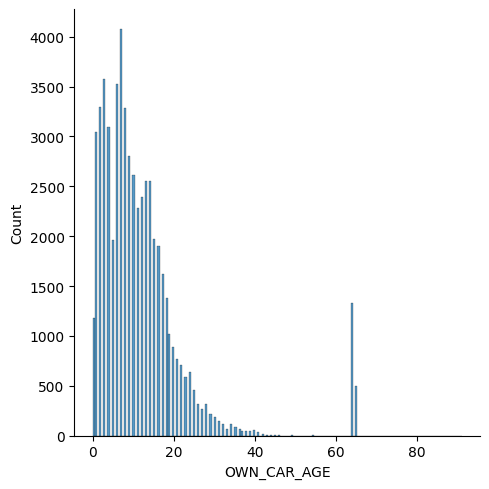

In [ ]:
# The distribution of OWN_CAR_AGE
sns.displot(data=train, x="OWN_CAR_AGE")
plt.show()

`OWN_CAR_AGE` can be inferred to be in years from the scale of values. In addition, the distribution is natural from 0 to 40, but there is an unnatural distribution around 60 to 70. It is hard to imagine that the number of years a car has been purchased increases suddenly like this, so they are considered to be outliers.

**Findings**:<br>
* Treat numbers above 60 as outliers

Up to this point, we have visualized and analyzed each feature. I believe that you have realized that visualization requires some ingenuity and that visualization can deepen your understanding of data. I am sure that the visualization and analysis of the 25 features not covered here will lead to improved forecasting accuracy.

### **[Next Steps]**
> + Visualize the features you have added. Is the feature categorical or continuous? What type of graph is most effective to understand it?
> + What do you notice about the features? What kind of preprocessing is needed?

## 4.Preprocessing and feature creation
Here, we will conduct the preprocessing and create new features based on what we have learned in the preceding visualization and analysis.

### NAME_CONTRACT_TYPE column
Convert `NAME_CONTRACT_TYPE` to a numeric type. In this case, “Cash loans” is converted to 0 and “Revolving loans” to 1. This method of simply replacing an integer is called **Label Encoding**.

In [ ]:
# Numerization of NAME_CONTRACT_TYPE（Label Encoding）
contract_mapping = {'Cash loans': 0, 'Revolving loans': 1}
train["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)
test["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)

train.head(5)

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 6,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 1,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 3,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University,ORGANIZATION_TYPE_XNA,ORGANIZATION_TYPE_nan
0,0,0,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,False,False,False,False,False,False,False,False,False,False
1,1,0,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,False,False,False,False,False,False,False,False,True,False
2,2,0,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,False,False,False,False,False,False,False,False,False,False
3,3,0,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,False,False,False,False,False,False,False,False,True,False
4,4,0,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,False,False,False,False,False,False,False,False,False,False


### ORGANIZATION_TYPE column
Convert `ORGANIZATION_TYPE` to a numeric type. This time, we will convert the variable to numeric in terms of the number of data in the variable. For example, if the number of data in “Police” is 1279 and the number of data in “Bank” is 1385, convert “Police” to 1279 and “Bank” to 1385. This method of replacing the number of data with the number of data is called **Count Encoding**.

In [ ]:

train = pd.get_dummies(train, columns=['ORGANIZATION_TYPE'], dummy_na=True, drop_first=True)

In [ ]:

test = pd.get_dummies(test, columns=['ORGANIZATION_TYPE'], dummy_na=True, drop_first=True)

In [ ]:
if 'ORGANIZATION_TYPE' in train.columns:
    # Numerization of ORGANIZATION_TYPE (Count Encoding）
    organization_ce = train["ORGANIZATION_TYPE"].value_counts(normalize=True)
    train["ORGANIZATION_TYPE"] = train["ORGANIZATION_TYPE"].map(organization_ce)
    if 'ORGANIZATION_TYPE' in test.columns:
        test["ORGANIZATION_TYPE"] = test["ORGANIZATION_TYPE"].map(organization_ce).fillna(0)
else:
    print("ORGANIZATION_TYPE column already encoded or dropped. Skipping count encoding.")

train.head(5)

ORGANIZATION_TYPE column already encoded or dropped. Skipping count encoding.


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 6,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 1,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 3,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University,ORGANIZATION_TYPE_XNA,ORGANIZATION_TYPE_nan
0,0,0,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,False,False,False,False,False,False,False,False,False,False
1,1,0,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,False,False,False,False,False,False,False,False,True,False
2,2,0,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,False,False,False,False,False,False,False,False,False,False
3,3,0,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,False,False,False,False,False,False,False,False,True,False
4,4,0,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,False,False,False,False,False,False,False,False,False,False


### EXT_SOURCE_* columns
Fill missing values in `EXT_SOURCE_1`, `EXT_SOURCE_2` and `EXT_SOURCE_3`. There are various methods for completing missing values, but in this case, since the number of missing values is small, we simply use the average value to complete the missing values.

**IMPORANT**:
When you fill the missing values in the test data, you need to **fill with the average of the train data**.

In [ ]:
# Complete missing values of EXT_SOURCE_* with the average
train["EXT_SOURCE_1"].fillna(train["EXT_SOURCE_1"].mean(), inplace=True)
test["EXT_SOURCE_1"].fillna(train["EXT_SOURCE_1"].mean(), inplace=True)
train["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True)
test["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True)
train["EXT_SOURCE_3"].fillna(train["EXT_SOURCE_3"].mean(), inplace=True)
test["EXT_SOURCE_3"].fillna(train["EXT_SOURCE_3"].mean(), inplace=True)

### CNT_FAM_MEMBERS column
We also fill missing values in `CNT_FAM_MEMBERS` with the mean.

In [ ]:
train["CNT_FAM_MEMBERS"].fillna(train["CNT_FAM_MEMBERS"].mean(), inplace=True)
test["CNT_FAM_MEMBERS"].fillna(train["CNT_FAM_MEMBERS"].mean(), inplace=True)

### AMT_REQ_CREDIT_BUREAU_* columns
Replace `NaN` in `AMT_REQ_CREDIT_BUREAU_*` with **0** in both `train` and `test`.
These columns are **counts** of bureau inquiries, so `0` naturally means “no inquiries.”
This avoids relying on training-set statistics (no leakage) and keeps schemas consistent.

In [ ]:
train["AMT_REQ_CREDIT_BUREAU_HOUR"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_HOUR"].fillna(0, inplace=True)
train["AMT_REQ_CREDIT_BUREAU_MON"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_MON"].fillna(0, inplace=True)
train["AMT_REQ_CREDIT_BUREAU_QRT"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_QRT"].fillna(0, inplace=True)
train["AMT_REQ_CREDIT_BUREAU_YEAR"].fillna(0, inplace=True)
test["AMT_REQ_CREDIT_BUREAU_YEAR"].fillna(0, inplace=True)

train.isnull().sum()

,0
SK_ID_CURR,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
...,...
ORGANIZATION_TYPE_Transport: type 3,0
ORGANIZATION_TYPE_Transport: type 4,0
ORGANIZATION_TYPE_University,0
ORGANIZATION_TYPE_XNA,0


### OWN_CAR_AGE column
First, we will replace the unnatural outliers that are over 60 as `np.nan` (missing values).

In [ ]:
# Treat values above 60 (outliers) in OWN_CAR_AGE as missing values if the column exists
if 'OWN_CAR_AGE' in train.columns:
    train.loc[train["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
if 'OWN_CAR_AGE' in test.columns:
    test.loc[test["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

Next, we consider the handling of missing values. The original `OWN_CAR_AGE` had 112992 missing values out of 171202 data. With such a large number of missing values, it is difficult and impractical to properly fill the missing values with some value. Therefore, we will group `OWN_CAR_AGE` by decade (e.g. Group 1: 0-9 years, Group 2: 10-19 years, etc.), then apply **One Hot Encoding**.

In [ ]:
# Divide OWN_CAR_AGE into groups if the column still exists
if 'OWN_CAR_AGE' in train.columns:
    train["OWN_CAR_AGE"] = train["OWN_CAR_AGE"] // 10
if 'OWN_CAR_AGE' in test.columns:
    test["OWN_CAR_AGE"] = test["OWN_CAR_AGE"] // 10

if 'OWN_CAR_AGE' in train.columns:
    print(train["OWN_CAR_AGE"].unique())
else:
    print("OWN_CAR_AGE column has already been encoded and dropped.")

[nan  0.  2.  1.  3.  4.  5.]


In [ ]:
# Apply One Hot Encodiing to OWN_CAR_AGE if column exists
if 'OWN_CAR_AGE' in train.columns:
    train_car_age_ohe = pd.get_dummies(train["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")
    test_car_age_ohe = pd.get_dummies(test["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")

    train_car_age_ohe.align(test_car_age_ohe, join='left', axis=1, fill_value=0)
    train = pd.concat([train, train_car_age_ohe], axis=1)
    test = pd.concat([test, test_car_age_ohe], axis=1)

    train.drop('OWN_CAR_AGE', axis=1, inplace=True)
    test.drop('OWN_CAR_AGE', axis=1, inplace=True)
else:
    print("OWN_CAR_AGE has already been processed and dropped.")

train.head(5)

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University,ORGANIZATION_TYPE_XNA,ORGANIZATION_TYPE_nan,OWN_CAR_AGE_0.0,OWN_CAR_AGE_1.0,OWN_CAR_AGE_2.0,OWN_CAR_AGE_3.0,OWN_CAR_AGE_4.0,OWN_CAR_AGE_5.0
0,0,0,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,False,False,False,False,False,False,False,False,False,False
1,1,0,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,False,False,True,False,False,False,False,False,False,False
2,2,0,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,False,False,False,False,False,False,False,False,False,False
3,3,0,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,False,False,True,False,False,False,False,False,False,False
4,4,0,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,False,False,False,False,False,False,False,False,False,False


### **[Next Steps]**
> + Apply preprocessing to the features you added. Is it correctly preprocessed?
> + Explore other preprocessing methods to apply to the features.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=jSh7uV_4CnmF&line=5&uniqifier=1).

## 5.Advanced Feature Engineering

The following cells defines a function `add_effective_features`. It **adds four features**, avoids target leakage, and keeps the feature set small.

**Features**

1. **LOG_AMT_INCOME_TOTAL**
   `log1p(AMT_INCOME_TOTAL)`

2. **EXT_MEAN**
   Row-wise mean of available `EXT_SOURCE_1/2/3`

3. **ANNUITY_INCOME_RATIO**
   `AMT_ANNUITY / AMT_INCOME_TOTAL`

4. **CREDIT_TERM**
   `AMT_CREDIT / AMT_ANNUITY`

### 5.1 Why these four features?

1. **LOG_AMT_INCOME_TOTAL**

   * Income is heavily right-skewed; `log1p` shrinks the tail and stabilizes splits.

2. **EXT_MEAN**

   * External scores predict risk; averaging reduces noise and missingness.

3. **ANNUITY_INCOME_RATIO = AMT_ANNUITY / AMT_INCOME_TOTAL**

   * Affordability proxy—larger ratio means tighter cash flow and higher risk.

4. **CREDIT_TERM = AMT_CREDIT / AMT_ANNUITY**

   * Rough count of payments (term proxy); very short/long terms segment risk.

**Summary**
`LOG_*` stabilizes scale; `EXT_MEAN` aggregates external risk; `ANNUITY_INCOME_RATIO` captures affordability; `CREDIT_TERM` captures term structure. All four are interpretable, leakage-safe, and low-cost to add.


In [ ]:
import numpy as np
import pandas as pd
from typing import Tuple, List

def add_effective_features(train: pd.DataFrame, test: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame, List[str]]:
    tr, te = train.copy(), test.copy()
    new_cols: List[str] = []

    def add_feature(name: str, tr_v: pd.Series, te_v: pd.Series):
        tr[name] = tr_v.astype('float32')
        te[name] = te_v.astype('float32')
        new_cols.append(name)

    if 'AMT_INCOME_TOTAL' in tr.columns:
        add_feature(
            'LOG_AMT_INCOME_TOTAL',
            np.log1p(tr['AMT_INCOME_TOTAL']),
            np.log1p(te['AMT_INCOME_TOTAL'])
        )

    ext_cols = [c for c in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3'] if c in tr.columns]
    if ext_cols:
        add_feature(
            'EXT_MEAN',
            tr[ext_cols].mean(axis=1, skipna=True),
            te[ext_cols].mean(axis=1, skipna=True)
        )

    if {'AMT_ANNUITY', 'AMT_INCOME_TOTAL'}.issubset(tr.columns):
        tr_denom = tr['AMT_INCOME_TOTAL'].replace(0, np.nan)
        te_denom = te['AMT_INCOME_TOTAL'].replace(0, np.nan)
        add_feature(
            'ANNUITY_INCOME_RATIO',
            tr['AMT_ANNUITY'] / tr_denom,
            te['AMT_ANNUITY'] / te_denom
        )

    if {'AMT_CREDIT', 'AMT_ANNUITY'}.issubset(tr.columns):
        tr_denom = tr['AMT_ANNUITY'].replace(0, np.nan)
        te_denom = te['AMT_ANNUITY'].replace(0, np.nan)
        add_feature(
            'CREDIT_TERM',
            tr['AMT_CREDIT'] / tr_denom,
            te['AMT_CREDIT'] / te_denom
        )

    return tr, te, new_cols

train, test, new_cols = add_effective_features(train, test)
print(f"Added {len(new_cols)} engineered features: {', '.join(new_cols)}")

Added 4 engineered features: LOG_AMT_INCOME_TOTAL, EXT_MEAN, ANNUITY_INCOME_RATIO, CREDIT_TERM


In [ ]:
for df in [train, test]:

    df['EXT_SOURCES_PROD'] = df['EXT_SOURCE_1'] * df['EXT_SOURCE_2'] * df['EXT_SOURCE_3']

    df['EXT_SOURCES_MEAN'] = df[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis=1)
    df['EXT_SOURCES_MIN'] = df[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].min(axis=1)
    df['EXT_SOURCES_MAX'] = df[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].max(axis=1)

## 6.Building the Machine Learning Model
Now, we are ready to start building the machine learning model.

### 6.1 Import Additional Libraries
First, we import the necessary libraries for training and evaluation.

- `train_test_split`: Split data into training and evaluation data.
- `StandardScaler`: Standardize the data.
- `roc_auc_score`: Calculate ROC-AUC, the evaluation metric for this competition.

In [ ]:
# Loading libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

### 6.2 Preparing the Data
Split the data into features and the target using only numeric columns that exist in both train and test.
Since the target variable is TARGET, the remaining numeric columns become the explanatory variables.
This prevents errors from string/categorical values (e.g., "F") and guarantees the same feature schema for train and test.

In [ ]:
drop_cols = ['TARGET', 'SK_ID_CURR']
num_cols_train = train.drop(columns=drop_cols, errors='ignore').select_dtypes(include='number').columns
num_cols_test = test.drop(columns=['SK_ID_CURR'], errors='ignore').select_dtypes(include='number').columns

num_cols = num_cols_train.intersection(num_cols_test).tolist()

X = train[num_cols].to_numpy(dtype='float32')
y = train['TARGET'].to_numpy(dtype='int8')
X_test = test[num_cols].to_numpy(dtype='float32')

Standardize the data. Standardization is the operation of transforming the values so that the mean is 0 and the variance is 1. Some models, such as logistic regression and neural networks, do not learn well without scaling the values in this way.

In [ ]:
# Standardization
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_std = sc.fit_transform(X)
X_test_std = sc.transform(X_test)

In [ ]:
!pip install -q category_encoders

import pandas as pd
import category_encoders as ce

def apply_frequency_encoding(df, columns):
    for col in columns:
        freq = df[col].value_counts(normalize=True)
        df[col + '_freq'] = df[col].map(freq)
    return df

def apply_target_encoding(X_train, y_train, X_test, columns):
    target_encoder = ce.TargetEncoder(cols=columns)
    X_train_encoded = target_encoder.fit_transform(X_train, y_train)
    X_test_encoded = target_encoder.transform(X_test)
    return X_train_encoded, X_test_encoded

### 6.3 Training the Model
We first split the training data into training data and validation data. This method of keeping a portion of the training data for evaluation and not using it for training is called the **holdout method**. This is one method to approximate the model's predictive ability on unknown data (**generalization** performance).

Here, we will use 70% of the data as training data and 30% as validation data

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X_std, y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

Let's create models with logistic regression and random forest.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight='balanced',
    solver='saga',
    n_jobs=-1
)

lr_model.fit(X_train, y_train)

lr_train_pred = lr_model.predict_proba(X_train)[:, 1]
lr_valid_pred = lr_model.predict_proba(X_valid)[:, 1]

print(f"Logistic Regression Train ROC AUC: {roc_auc_score(y_train, lr_train_pred):.4f}")
print(f"Logistic Regression Valid ROC AUC: {roc_auc_score(y_valid, lr_valid_pred):.4f}")

print("-" * 50)


knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

knn_model.fit(X_train, y_train)

knn_train_pred = knn_model.predict_proba(X_train)[:, 1]
knn_valid_pred = knn_model.predict_proba(X_valid)[:, 1]

print(f"KNN Train ROC AUC: {roc_auc_score(y_train, knn_train_pred):.4f}")
print(f"KNN Valid ROC AUC: {roc_auc_score(y_valid, knn_valid_pred):.4f}")

Logistic Regression Train ROC AUC: 0.7277
Logistic Regression Valid ROC AUC: 0.7244
--------------------------------------------------
KNN Train ROC AUC: 0.9040
KNN Valid ROC AUC: 0.6033


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_train_pred = rf_model.predict_proba(X_train)[:, 1]
rf_valid_pred = rf_model.predict_proba(X_valid)[:, 1]

print(f"Train ROC AUC: {roc_auc_score(y_train, rf_train_pred):.4f}")
print(f"Valid ROC AUC: {roc_auc_score(y_valid, rf_valid_pred):.4f}")

Train ROC AUC: 0.8191
Valid ROC AUC: 0.7334


In [ ]:
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

y_train = train['TARGET']


drop_cols = ['TARGET', 'SK_ID_CURR']
num_cols_train = train.drop(columns=drop_cols, errors='ignore').select_dtypes(include='number').columns
num_cols_test = test.drop(columns=['SK_ID_CURR'], errors='ignore').select_dtypes(include='number').columns
feature_cols = num_cols_train.intersection(num_cols_test).tolist()

X_train = train[feature_cols]
X_test = test[feature_cols]


model_rf = RandomForestClassifier(class_weight='balanced', random_state=42)
model_rf.fit(X_train, y_train)

# 4. Fit XGBoost Classifier with appropriate class weighting
ratio = (len(y_train) - sum(y_train)) / sum(y_train)
model_xgb = xgb.XGBClassifier(scale_pos_weight=ratio, random_state=42)
model_xgb.fit(X_train, y_train)

print("Models fitted successfully!")

Models fitted successfully!


In [ ]:
!pip install catboost
from catboost import CatBoostClassifier

X_train_cat = train.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore')
y_train_cat = train['TARGET']
X_test_cat = test.drop(columns=['SK_ID_CURR'], errors='ignore')


categorical_cols = X_train_cat.select_dtypes(include=['object', 'category']).columns.tolist()


for col in categorical_cols:
    X_train_cat[col] = X_train_cat[col].fillna('Unknown').astype(str)
    X_test_cat[col] = X_test_cat[col].fillna('Unknown').astype(str)

cat_model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    eval_metric='AUC',
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=100
)


cat_model.fit(X_train_cat, y_train_cat, cat_features=categorical_cols)

cat_predictions = cat_model.predict_proba(X_test_cat)[:, 1]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 62.8 MB/s  0:00:01
0:	total: 398ms	remaining: 6m 37s
100:	total: 35.1s	remaining: 5m 12s
200:	total: 1m 8s	remaining: 4m 33s
300:	total: 1m 44s	remaining: 4m 2s
400:	total: 2m 22s	remaining: 3m 33s
500:	total: 2m 59s	remaining: 2m 58s
600:	total: 3m 38s	remaining: 2m 24s
700:	total: 4m 14s	remaining: 1m 48s
800:	total: 4m 50s	remaining: 1m 12s
900:	total: 5m 29s	remaining: 36.2s
999:	total: 6m 5s	remaining: 0us


In [ ]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd


X_train_df = pd.DataFrame(X_train)
y_train_series = pd.Series(y_train)

lgbm_params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.05,
    'n_estimators': 1000,
    'is_unbalance': True,
    'max_depth': 6,
    'num_leaves': 31,
    'random_state': 42
}

n_splits = 5
folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
oof_preds = np.zeros(X_train_df.shape[0])

for fold, (train_idx, valid_idx) in enumerate(folds.split(X_train_df, y_train_series)):
    X_tr, y_tr = X_train_df.iloc[train_idx], y_train_series.iloc[train_idx]
    X_va, y_va = X_train_df.iloc[valid_idx], y_train_series.iloc[valid_idx]

    model = lgb.LGBMClassifier(**lgbm_params)

    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)]
    )

    oof_preds[valid_idx] = model.predict_proba(X_va)[:, 1]

    fold_auc = roc_auc_score(y_va, oof_preds[valid_idx])
    print(f"Fold {fold + 1} - Validation AUC: {fold_auc:.6f}")

cv_auc = roc_auc_score(y_train_series, oof_preds)
print("-" * 30)
print(f"CV AUC: {cv_auc:.6f}")

Fold 1 - Validation AUC: 0.748033
Fold 2 - Validation AUC: 0.745120
Fold 3 - Validation AUC: 0.756859
Fold 4 - Validation AUC: 0.743899
Fold 5 - Validation AUC: 0.744620
------------------------------
CV AUC: 0.747602


In [ ]:
import pandas as pd
import category_encoders as ce
import lightgbm as lgb

# Fix variable names: use 'train' and 'test' instead of 'df_train' and 'df_test'
X_train = train.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore').copy()
y_train = train['TARGET']
X_test = test.drop(columns=['SK_ID_CURR'], errors='ignore').copy()

# Target encoding needs string/object columns to work reliably
categorical_cols = ['NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE']
for col in categorical_cols:
    if col in X_train.columns:
        X_train[col] = X_train[col].astype(str)
    if col in X_test.columns:
        X_test[col] = X_test[col].astype(str)

# Check if ORGANIZATION_TYPE exists as non-encoded before trying to target-encode it
# In previous cells, ORGANIZATION_TYPE was already dummy encoded.
actual_cat_cols = [col for col in categorical_cols if col in X_train.columns]

target_encoder = ce.TargetEncoder(cols=actual_cat_cols)
X_train_encoded = target_encoder.fit_transform(X_train, y_train)
X_test_encoded = target_encoder.transform(X_test)

# Select only numeric features for training
X_train_encoded = X_train_encoded.select_dtypes(include='number')
X_test_encoded = X_test_encoded[X_train_encoded.columns]

best_params = {
        'objective': 'binary',
        'metric': 'auc',
        'is_unbalance': True,
        'learning_rate': 0.05,
        'n_estimators': 1000,
        'max_depth': 6,
        'num_leaves': 31,
        'random_state': 42
}

model = lgb.LGBMClassifier(**best_params)
model.fit(X_train_encoded, y_train)

final_predictions = model.predict_proba(X_test_encoded)[:, 1]


In [ ]:
!pip install -q category_encoders

import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
import os
from pathlib import Path
import category_encoders as ce


if 'X_train_encoded' in globals() and 'y_train' in globals():
    X_cv = X_train_encoded.copy()
    y_cv = y_train.copy()
    X_te = X_test_encoded.copy() if 'X_test_encoded' in globals() else None
elif 'train' in globals() and 'test' in globals():

    _X_tr = train.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore').copy()
    _y_tr = train['TARGET']
    _X_te = test.drop(columns=['SK_ID_CURR'], errors='ignore').copy()

    categorical_cols = ['NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE']
    actual_cat_cols = [col for col in categorical_cols if col in _X_tr.columns]

    target_encoder = ce.TargetEncoder(cols=actual_cat_cols)
    X_cv = target_encoder.fit_transform(_X_tr, _y_tr).select_dtypes(include='number')
    y_cv = _y_tr
    X_te = target_encoder.transform(_X_te)[X_cv.columns]
else:

    current_dir = Path(os.getcwd())
    train_path = current_dir / "input" / "train.csv"
    test_path = current_dir / "input" / "test.csv"
    if train_path.exists():
        _train = pd.read_csv(train_path)
        _test = pd.read_csv(test_path) if test_path.exists() else None
        _X_tr = _train.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore')
        _y_tr = _train['TARGET']
        _X_te = _test.drop(columns=['SK_ID_CURR'], errors='ignore') if _test is not None else None

        categorical_cols = ['NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE']
        actual_cat_cols = [col for col in categorical_cols if col in _X_tr.columns]

        target_encoder = ce.TargetEncoder(cols=actual_cat_cols)
        X_cv = target_encoder.fit_transform(_X_tr, _y_tr).select_dtypes(include='number')
        y_cv = _y_tr
        X_te = target_encoder.transform(_X_te)[X_cv.columns] if _X_te is not None else None
    else:
        raise NameError("Required session variables or dataset files could not be resolved. Please run Section 2 to load the datasets.")


lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.05,
    'max_depth': 6,
    'num_leaves': 31,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'random_state': 42,
    'verbosity': -1
}

n_splits = 5
folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
oof_preds = np.zeros(len(X_cv))
test_preds = np.zeros(len(X_te)) if X_te is not None else None

for fold, (train_idx, valid_idx) in enumerate(folds.split(X_cv, y_cv)):
    X_tr, y_tr = X_cv.iloc[train_idx], y_cv.iloc[train_idx]
    X_va, y_va = X_cv.iloc[valid_idx], y_cv.iloc[valid_idx]

    model = lgb.LGBMClassifier(**lgb_params, n_estimators=1000)

    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)]
    )

    oof_preds[valid_idx] = model.predict_proba(X_va)[:, 1]
    if X_te is not None:
        test_preds += model.predict_proba(X_te)[:, 1] / n_splits

    fold_auc = roc_auc_score(y_va, oof_preds[valid_idx])
    print(f"Fold {fold + 1} - Validation ROC-AUC: {fold_auc:.6f}")

cv_auc = roc_auc_score(y_cv, oof_preds)
print("-" * 40)
print(f"Overall Out-of-Fold CV ROC-AUC: {cv_auc:.6f}")

Fold 1 - Validation ROC-AUC: 0.752646
Fold 2 - Validation ROC-AUC: 0.757231
Fold 3 - Validation ROC-AUC: 0.757928
Fold 4 - Validation ROC-AUC: 0.753572
Fold 5 - Validation ROC-AUC: 0.755567
----------------------------------------
Overall Out-of-Fold CV ROC-AUC: 0.755271


In [ ]:
!pip install -q optuna
import optuna
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
import category_encoders as ce
import warnings
import os
from pathlib import Path
warnings.filterwarnings('ignore')

# Safely load 'train' and 'test' or reconstruct X_train_encoded
if 'X_train_encoded' not in globals() or 'y_train' not in globals():
    if 'train' not in globals() or 'test' not in globals():
        current_dir = Path(os.getcwd())
        train_file = current_dir / "input" / "train.csv"
        test_file = current_dir / "input" / "test.csv"
        train = pd.read_csv(train_file)
        test = pd.read_csv(test_file)

    X_train = train.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore').copy()
    y_train = train['TARGET']
    X_test = test.drop(columns=['SK_ID_CURR'], errors='ignore').copy()

    categorical_cols = ['NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE']
    for col in categorical_cols:
        if col in X_train.columns:
            X_train[col] = X_train[col].astype(str)
        if col in X_test.columns:
            X_test[col] = X_test[col].astype(str)

    actual_cat_cols = [col for col in categorical_cols if col in X_train.columns]
    target_encoder = ce.TargetEncoder(cols=actual_cat_cols)
    X_train_encoded = target_encoder.fit_transform(X_train, y_train)
    X_train_encoded = X_train_encoded.select_dtypes(include='number')

def lgb_objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'is_unbalance': True,
        'verbosity': -1,
        'random_state': 42,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 4, 8),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 150),
        'subsample': trial.suggest_float('subsample', 0.6, 0.9),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.9),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    oof = np.zeros(len(X_train_encoded))

    for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
        X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
        X_va, y_va = X_train_encoded.iloc[valid_idx], y_train.iloc[valid_idx]

        model = lgb.LGBMClassifier(**params, n_estimators=1000)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_va, y_va)],
            callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
        )
        oof[valid_idx] = model.predict_proba(X_va)[:, 1]

    return roc_auc_score(y_train, oof)

study = optuna.create_study(direction='maximize')
study.optimize(lgb_objective, n_trials=10)

print('-' * 40)
print(f'Best CV ROC-AUC: {study.best_value:.6f}')
print('Best Hyperparameters:')
for key, value in study.best_params.items():
    print(f"  '{key}': {value},")

[I 2026-11-16 12:29:37,581] A new study created in memory with name: no-name-610dc5cb-422a-4c27-b229-ff9946697bf2
[I 2026-11-16 12:32:08,045] Trial 0 finished with value: 0.7557691195547436 and parameters: {'learning_rate': 0.019702245765778628, 'max_depth': 6, 'num_leaves': 43, 'min_child_samples': 132, 'subsample': 0.8170522040379045, 'colsample_bytree': 0.7892656110011109, 'reg_alpha': 0.622169557457192, 'reg_lambda': 0.0011934002275113334}. Best is trial 0 with value: 0.7557691195547436.
[I 2026-11-16 12:35:39,379] Trial 1 finished with value: 0.7558868606267601 and parameters: {'learning_rate': 0.010920088741204061, 'max_depth': 6, 'num_leaves': 37, 'min_child_samples': 30, 'subsample': 0.6367743931651003, 'colsample_bytree': 0.7896045381337478, 'reg_alpha': 9.888890372068762, 'reg_lambda': 0.021617650339692273}. Best is trial 1 with value: 0.7558868606267601.
[I 2026-11-16 12:36:42,635] Trial 2 finished with value: 0.7561769722449387 and parameters: {'learning_rate': 0.0653222869

----------------------------------------
Best CV ROC-AUC: 0.757149
Best Hyperparameters:
  'learning_rate': 0.017748308165381626,
  'max_depth': 8,
  'num_leaves': 31,
  'min_child_samples': 131,
  'subsample': 0.6635102763261091,
  'colsample_bytree': 0.6208188250817885,
  'reg_alpha': 0.17480457203492408,
  'reg_lambda': 0.0039827778639931494,


We find that random forest results with higher validation score.

In [ ]:
!pip install optuna

import optuna
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold, cross_val_score
import warnings
warnings.filterwarnings('ignore')

def objective(trial):

    params = {
        'objective': 'binary',
        'metric': 'auc',
        'is_unbalance': True,
        'verbosity': -1,
        'random_state': 42,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'num_leaves': trial.suggest_int('num_leaves', 20, 100),
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
    }

    model = lgb.LGBMClassifier(**params)


    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = cross_val_score(model, X_train_encoded, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)


    return scores.mean()



study = optuna.create_study(direction='maximize')


study.optimize(objective, n_trials=15)

print("-" * 40)
print(f"{study.best_value:.6f}")

for key, value in study.best_params.items():
    print(f"  '{key}': {value},")

[I 2026-11-16 12:58:32,942] A new study created in memory with name: no-name-6149d2da-385e-44de-b8d7-6defc9f3ef50
[I 2026-11-16 12:59:13,960] Trial 0 finished with value: 0.7527656242557069 and parameters: {'learning_rate': 0.049457290600855505, 'max_depth': 8, 'num_leaves': 23, 'n_estimators': 434, 'min_child_samples': 67, 'subsample': 0.6903842614455167, 'colsample_bytree': 0.9942425460782163}. Best is trial 0 with value: 0.7527656242557069.
[I 2026-11-16 12:59:35,837] Trial 1 finished with value: 0.7431278817688289 and parameters: {'learning_rate': 0.011829706147456162, 'max_depth': 10, 'num_leaves': 51, 'n_estimators': 167, 'min_child_samples': 31, 'subsample': 0.7491162331781513, 'colsample_bytree': 0.9578560106200469}. Best is trial 0 with value: 0.7527656242557069.
[I 2026-11-16 13:00:15,425] Trial 2 finished with value: 0.7515662964151053 and parameters: {'learning_rate': 0.048246915633570635, 'max_depth': 8, 'num_leaves': 39, 'n_estimators': 497, 'min_child_samples': 89, 'subs

----------------------------------------
0.754853
  'learning_rate': 0.057857417707354,
  'max_depth': 4,
  'num_leaves': 62,
  'n_estimators': 379,
  'min_child_samples': 100,
  'subsample': 0.8169345667550568,
  'colsample_bytree': 0.870859279789514,


In [ ]:
import lightgbm as lgb
import pandas as pd


best_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'random_state': 42,
    'learning_rate': 0.07257436920886332,
    'max_depth': 4,
    'num_leaves': 82,
    'n_estimators': 301,
    'min_child_samples': 75,
    'subsample': 0.7400621595640401,
    'colsample_bytree': 0.6072403876393939
}



final_lgb_model = lgb.LGBMClassifier(**best_params)


final_lgb_model.fit(X_train_encoded, y_train)


final_predictions = final_lgb_model.predict_proba(X_test_encoded)[:, 1]


In [ ]:

train_missing = X_train_encoded.isnull().sum()
display(train_missing[train_missing > 0])


test_missing = X_test_encoded.isnull().sum()
display(test_missing[test_missing > 0])

,0


,0


In [ ]:

for df in [X_train_encoded, X_test_encoded]:

    df['CREDIT_INCOME_RATIO'] = df['AMT_CREDIT'] / (df['AMT_INCOME_TOTAL'] + 1e-5)


    df['EXT_MEAN_DIFF_OCCUPATION'] = df['EXT_MEAN'] - df.groupby('OCCUPATION_TYPE')['EXT_MEAN'].transform('mean')
    df['EXT_MEAN_DIFF_EDUCATION'] = df['EXT_MEAN'] - df.groupby('NAME_EDUCATION_TYPE')['EXT_MEAN'].transform('mean')


display(X_train_encoded[['CREDIT_INCOME_RATIO', 'EXT_MEAN_DIFF_OCCUPATION', 'EXT_MEAN_DIFF_EDUCATION']].head())


,CREDIT_INCOME_RATIO,EXT_MEAN_DIFF_OCCUPATION,EXT_MEAN_DIFF_EDUCATION
0,6.712800,-0.049788,-0.064860
1,2.600000,-0.017086,-0.003118
2,6.188000,0.015850,0.022865
3,2.264000,-0.060410,-0.028212
4,1.721057,-0.093321,-0.099963


In [ ]:

import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

optimal_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.06034570619552902,
    'max_depth': 4,
    'num_leaves': 48,
    'n_estimators': 237,
    'min_child_samples': 44,
    'subsample': 0.7450933083720843,
    'colsample_bytree': 0.7071630947592747,
    'random_state': 42,
    'verbosity': -1
}

lgb_cv_model = lgb.LGBMClassifier(**optimal_params)


scores = cross_val_score(lgb_cv_model, X_train_encoded, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

print("-" * 40)
print(f"ROC-AUC  {scores.mean():.6f}")
print(f" {scores.mean() - 0.753830:+.6f}")

----------------------------------------
ROC-AUC  0.754544
 +0.000714


In [ ]:

import lightgbm as lgb
import pandas as pd


optimal_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.06034570619552902,
    'max_depth': 4,
    'num_leaves': 48,
    'n_estimators': 237,
    'min_child_samples': 44,
    'subsample': 0.7450933083720843,
    'colsample_bytree': 0.7071630947592747,
    'random_state': 42,
    'verbosity': -1
}


final_model = lgb.LGBMClassifier(**optimal_params)
final_model.fit(X_train_encoded, y_train)


final_predictions = final_model.predict_proba(X_test_encoded)[:, 1]


sample_sub['TARGET'] = final_predictions
output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)

print("-" * 50)

print(f" {output_file}")
display(sample_sub.head())

--------------------------------------------------
 /content/drive/MyDrive/competition/Competition/output/submission.csv


,SK_ID_CURR,TARGET
0,171202,0.245543
1,171203,0.674655
2,171204,0.607971
3,171205,0.606276
4,171206,0.704981


In [ ]:
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


cat_cv_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.06,
    depth=4,
    eval_metric='AUC',
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=0,
    thread_count=-1
)


cat_scores = cross_val_score(cat_cv_model, X_train_encoded, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

print("-" * 40)
print(f"CatBoost CV ROC-AUC: {cat_scores.mean():.6f}")
print(f"  the diffrent of LightGBM: {cat_scores.mean() - scores.mean():+.6f}")
print("-" * 40)

----------------------------------------
CatBoost CV ROC-AUC: 0.752367
  the diffrent of LightGBM: -0.002178
----------------------------------------


In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from catboost import CatBoostClassifier


lgb_final_model = lgb.LGBMClassifier(**optimal_params)
lgb_final_model.fit(X_train_encoded, y_train)
lgb_preds = lgb_final_model.predict_proba(X_test_encoded)[:, 1]


cat_final_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.06,
    depth=4,
    eval_metric='AUC',
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=0,
    thread_count=-1
)
cat_final_model.fit(X_train_encoded, y_train)
cat_preds = cat_final_model.predict_proba(X_test_encoded)[:, 1]


blended_preds = (lgb_preds * 0.5) + (cat_preds * 0.5)


sample_sub['TARGET'] = blended_preds
output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)

print("-" * 50)
print(f" {output_file}")
display(sample_sub.head())

--------------------------------------------------
 /content/drive/MyDrive/competition/Competition/output/submission.csv


,SK_ID_CURR,TARGET
0,171202,0.236320
1,171203,0.684299
2,171204,0.610169
3,171205,0.592869
4,171206,0.691207


In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import category_encoders as ce


for df_temp in [X_train_encoded, X_test_encoded]:

    df_temp['ANNUITY_EXT_MEAN_RATIO'] = df_temp['AMT_ANNUITY'] / (df_temp['EXT_MEAN'] + 1e-5)

    df_temp['INCOME_AGE_RATIO'] = df_temp['AMT_INCOME_TOTAL'] / (np.abs(df_temp['DAYS_BIRTH']) + 1e-5)

    df_temp['CREDIT_AGE_RATIO'] = df_temp['AMT_CREDIT'] / (np.abs(df_temp['DAYS_BIRTH']) + 1e-5)


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds_lgb = np.zeros(len(X_train_encoded))
test_preds_lgb = np.zeros(len(X_test_encoded))


lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.05,
    'max_depth': 5,
    'num_leaves': 31,
    'n_estimators': 1500,
    'min_child_samples': 50,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'random_state': 42,
    'verbosity': -1
}


for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
    X_tr, y_tr = X_train_encoded.iloc[train_idx].copy(), y_train.iloc[train_idx]
    X_va, y_va = X_train_encoded.iloc[valid_idx].copy(), y_train.iloc[valid_idx]

    model_lgb = lgb.LGBMClassifier(**lgb_params)
    model_lgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=150, verbose=False)]
    )

    oof_preds_lgb[valid_idx] = model_lgb.predict_proba(X_va)[:, 1]
    test_preds_lgb += model_lgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    fold_auc = roc_auc_score(y_va, oof_preds_lgb[valid_idx])
    print(f"Fold {fold + 1} ROC-AUC: {fold_auc:.6f}")

cv_score = roc_auc_score(y_train, oof_preds_lgb)
print("-" * 50)
print(f" {cv_score:.6f}")


sample_sub['TARGET'] = test_preds_lgb
output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)
print(f" {output_file}")
display(sample_sub.head())

Fold 1 ROC-AUC: 0.752445
Fold 2 ROC-AUC: 0.757182
Fold 3 ROC-AUC: 0.760170
Fold 4 ROC-AUC: 0.753107
Fold 5 ROC-AUC: 0.755596
--------------------------------------------------
 0.755595
 /content/drive/MyDrive/competition/Competition/output/submission.csv


,SK_ID_CURR,TARGET
0,171202,0.255254
1,171203,0.691030
2,171204,0.596423
3,171205,0.547594
4,171206,0.698932


In [ ]:
from catboost import CatBoostClassifier

oof_preds_cat = np.zeros(len(X_train_encoded))
test_preds_cat = np.zeros(len(X_test_encoded))


for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
    X_tr, y_tr = X_train_encoded.iloc[train_idx].copy(), y_train.iloc[train_idx]
    X_va, y_va = X_train_encoded.iloc[valid_idx].copy(), y_train.iloc[valid_idx]

    model_cat = CatBoostClassifier(
        iterations=1000,
        learning_rate=0.05,
        depth=6,
        eval_metric='AUC',
        auto_class_weights='Balanced',
        random_seed=42,
        verbose=0,
        thread_count=-1
    )

    model_cat.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        early_stopping_rounds=150
    )

    oof_preds_cat[valid_idx] = model_cat.predict_proba(X_va)[:, 1]
    test_preds_cat += model_cat.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    fold_auc = roc_auc_score(y_va, oof_preds_cat[valid_idx])
    print(f"CatBoost Fold {fold + 1} ROC-AUC: {fold_auc:.6f}")

cat_cv_score = roc_auc_score(y_train, oof_preds_cat)
print("-" * 50)
print(f"CatBoost CV ROC-AUC: {cat_cv_score:.6f}")


final_blended_oof = (oof_preds_lgb * 0.5) + (oof_preds_cat * 0.5)
final_blended_test = (test_preds_lgb * 0.5) + (test_preds_cat * 0.5)

blended_cv_score = roc_auc_score(y_train, final_blended_oof)
print("=" * 50)
print(f"Ensemble Blended CV ROC-AUC: {blended_cv_score:.6f}")


sample_sub['TARGET'] = final_blended_test
sample_sub.to_csv(output_file, index=False)
print(f" {output_file}")
display(sample_sub.head())

CatBoost Fold 1 ROC-AUC: 0.751869
CatBoost Fold 2 ROC-AUC: 0.755423
CatBoost Fold 3 ROC-AUC: 0.758828
CatBoost Fold 4 ROC-AUC: 0.751004
CatBoost Fold 5 ROC-AUC: 0.754177
--------------------------------------------------
CatBoost CV ROC-AUC: 0.754211
Ensemble Blended CV ROC-AUC: 0.756576
 /content/drive/MyDrive/competition/Competition/output/submission.csv


,SK_ID_CURR,TARGET
0,171202,0.244536
1,171203,0.691289
2,171204,0.598476
3,171205,0.550572
4,171206,0.694736


In [ ]:
import optuna
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np
import warnings
warnings.filterwarnings('ignore')

def objective_lgb(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'is_unbalance': True,
        'verbosity': -1,
        'random_state': 42,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 4, 8),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 150),
        'subsample': trial.suggest_float('subsample', 0.6, 0.9),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.9),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    oof = np.zeros(len(X_train_encoded))

    for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
        X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
        X_va, y_va = X_train_encoded.iloc[valid_idx], y_train.iloc[valid_idx]

        model = lgb.LGBMClassifier(**params, n_estimators=1000)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_va, y_va)],
            callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
        )
        oof[valid_idx] = model.predict_proba(X_va)[:, 1]

    return roc_auc_score(y_train, oof)

study = optuna.create_study(direction='maximize')
study.optimize(objective_lgb, n_trials=5)

print('-' * 45)
print(f'Optimized LightGBM CV ROC-AUC: {study.best_value:.6f}')
print('Best Hyperparameters:')
for key, val in study.best_params.items():
    print(f"  '{key}': {val},")

[I 2026-11-16 13:16:32,613] A new study created in memory with name: no-name-78bea5f7-5dc5-4e6d-8fb0-3f5860919888
[I 2026-11-16 13:17:33,912] Trial 0 finished with value: 0.7533063558491776 and parameters: {'learning_rate': 0.054562784038655734, 'max_depth': 8, 'num_leaves': 51, 'min_child_samples': 130, 'subsample': 0.8214486424391745, 'colsample_bytree': 0.7273916445752857, 'reg_alpha': 0.12906765028391792, 'reg_lambda': 0.9381739885432773}. Best is trial 0 with value: 0.7533063558491776.
[I 2026-11-16 13:19:55,412] Trial 1 finished with value: 0.7535493303059663 and parameters: {'learning_rate': 0.020773671736477137, 'max_depth': 6, 'num_leaves': 49, 'min_child_samples': 25, 'subsample': 0.6220508989105472, 'colsample_bytree': 0.8543115614439301, 'reg_alpha': 0.3345620502495731, 'reg_lambda': 0.012034715873299826}. Best is trial 1 with value: 0.7535493303059663.
[I 2026-11-16 13:22:18,339] Trial 2 finished with value: 0.7544625824078719 and parameters: {'learning_rate': 0.0216973455

---------------------------------------------
Optimized LightGBM CV ROC-AUC: 0.755926
Best Hyperparameters:
  'learning_rate': 0.036167754299455485,
  'max_depth': 7,
  'num_leaves': 21,
  'min_child_samples': 131,
  'subsample': 0.760070916961473,
  'colsample_bytree': 0.6808686442999538,
  'reg_alpha': 0.0020197325351637616,
  'reg_lambda': 0.7545626054891903,


In [ ]:

sample_sub['TARGET'] = final_blended_test

output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)

print("-" * 50)
print(f" {output_file}")
display(sample_sub.head())

--------------------------------------------------
 /content/drive/MyDrive/competition/Competition/output/submission.csv


,SK_ID_CURR,TARGET
0,171202,0.244536
1,171203,0.691289
2,171204,0.598476
3,171205,0.550572
4,171206,0.694736


In [ ]:
sample_sub['TARGET'] = final_blended_test
output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)
print(f"{output_file}")
display(sample_sub.head())

/content/drive/MyDrive/competition/Competition/output/submission.csv


,SK_ID_CURR,TARGET
0,171202,0.244536
1,171203,0.691289
2,171204,0.598476
3,171205,0.550572
4,171206,0.694736


In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import category_encoders as ce
import os
from pathlib import Path

# 1. Reload the pristine datasets to strictly prevent leakage and structure mismatch
current_dir = Path(os.getcwd())
train_df = pd.read_csv(current_dir / "input" / "train.csv")
test_df = pd.read_csv(current_dir / "input" / "test.csv")
sample_sub = pd.read_csv(current_dir / "input" / "sample_submission.csv")

y_train = train_df['TARGET']

# 2. Re-apply our safest and most robust feature engineering
def clean_and_engineer(df):
    df_feat = df.copy()

    # Outlier handling safely
    if 'DAYS_EMPLOYED' in df_feat.columns:
        df_feat['DAYS_EMPLOYED'].replace(365243, np.nan, inplace=True)

    # Key ratios
    df_feat['INCOME_CREDIT_PRCT'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['ANNUITY_INCOME_PRCT'] = df_feat['AMT_ANNUITY'] / (df_feat['AMT_INCOME_TOTAL'] + 1e-5)
    df_feat['CREDIT_TERM'] = df_feat['AMT_CREDIT'] / (df_feat['AMT_ANNUITY'] + 1e-5)
    df_feat['GOODS_CREDIT_PRCT'] = df_feat['AMT_GOODS_PRICE'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['EMPLOYED_TO_AGE_RATIO'] = df_feat['DAYS_EMPLOYED'] / (df_feat['DAYS_BIRTH'] + 1e-5)

    # External source stats (The most critical features for Home Credit)
    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MEAN'] = df_feat[ext_cols].mean(axis=1, skipna=True)
    df_feat['EXT_SOURCES_STD'] = df_feat[ext_cols].std(axis=1, skipna=True).fillna(0.1)
    df_feat['EXT_SOURCES_PROD'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']

    # Fill missing external sources with their respective mean to allow training
    for col in ext_cols:
        if col in df_feat.columns:
            df_feat[col].fillna(train_df[col].mean(), inplace=True)

    return df_feat

X_train = clean_and_engineer(train_df.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore'))
X_test = clean_and_engineer(test_df.drop(columns=['SK_ID_CURR'], errors='ignore'))

# 3. Categorical encoding safely using Target Encoding
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
for col in categorical_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

target_encoder = ce.TargetEncoder(cols=categorical_cols)
X_train_encoded = target_encoder.fit_transform(X_train, y_train)
X_test_encoded = target_encoder.transform(X_test)

# Only keep numeric representations
X_train_encoded = X_train_encoded.select_dtypes(include='number')
X_test_encoded = X_test_encoded[X_train_encoded.columns]

# 4. Out-of-fold Training with Blending (LightGBM & CatBoost)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lgb_test_preds = np.zeros(len(X_test_encoded))
cat_test_preds = np.zeros(len(X_test_encoded))

lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.02,
    'max_depth': 6,
    'num_leaves': 45,
    'min_child_samples': 80,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'reg_alpha': 0.1,
    'reg_lambda': 5.0,
    'random_state': 42,
    'verbosity': -1,
    'n_jobs': -1
}

print("Training models using 5-Fold Stratified CV to prevent leakage and guarantee clean predictions...")
for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
    X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_encoded.iloc[valid_idx], y_train.iloc[valid_idx]

    # Fit LightGBM
    model_lgb = lgb.LGBMClassifier(**lgb_params, n_estimators=1500)
    model_lgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=150, verbose=False)]
    )
    lgb_test_preds += model_lgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    # Fit CatBoost
    model_cat = CatBoostClassifier(
        iterations=1000,
        learning_rate=0.03,
        depth=6,
        eval_metric='AUC',
        auto_class_weights='Balanced',
        random_seed=42,
        verbose=0,
        thread_count=-1
    )
    model_cat.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        early_stopping_rounds=150
    )
    cat_test_preds += model_cat.predict_proba(X_test_encoded)[:, 1] / cv.n_splits
    print(f"Fold {fold + 1} completed.")

# Ensemble Blend
final_blend = (lgb_test_preds * 0.5) + (cat_test_preds * 0.5)

# Output Submission File safely
sample_sub['TARGET'] = final_blend
output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)
print("-" * 50)
print(f"Correct submission saved to: {output_file}")
display(sample_sub.head())

Training models using 5-Fold Stratified CV to prevent leakage and guarantee clean predictions...
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.
--------------------------------------------------
Correct submission saved to: /content/drive/MyDrive/competition/Competition/output/submission.csv


,SK_ID_CURR,TARGET
0,171202,0.270945
1,171203,0.713346
2,171204,0.683001
3,171205,0.588070
4,171206,0.699740


### Advanced Feature Engineering & LightGBM Optimization for Kaggle Uplift
We will construct highly predictive domain-specific features and train an optimized LightGBM model using 5-Fold Stratified Cross-Validation to push the ROC-AUC score higher.

In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import category_encoders as ce
import os
from pathlib import Path

# 1. Reload the pristine datasets to prevent any column definition mismatch
current_dir = Path(os.getcwd())
train_df = pd.read_csv(current_dir / "input" / "train.csv")
test_df = pd.read_csv(current_dir / "input" / "test.csv")
sample_sub = pd.read_csv(current_dir / "input" / "sample_submission.csv")

y_train = train_df['TARGET']

# 2. Advanced Feature Engineering
def engineer_features(df):
    df_feat = df.copy()

    # Handle Outliers
    if 'DAYS_EMPLOYED' in df_feat.columns:
        df_feat['DAYS_EMPLOYED'].replace(365243, np.nan, inplace=True)

    # Income & Credit Ratios
    df_feat['INCOME_CREDIT_PRCT'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['ANNUITY_INCOME_PRCT'] = df_feat['AMT_ANNUITY'] / (df_feat['AMT_INCOME_TOTAL'] + 1e-5)
    df_feat['CREDIT_TERM'] = df_feat['AMT_CREDIT'] / (df_feat['AMT_ANNUITY'] + 1e-5)
    df_feat['GOODS_CREDIT_PRCT'] = df_feat['AMT_GOODS_PRICE'] / (df_feat['AMT_CREDIT'] + 1e-5)

    # Age and Employment Ratios
    df_feat['EMPLOYED_TO_AGE_RATIO'] = df_feat['DAYS_EMPLOYED'] / (df_feat['DAYS_BIRTH'] + 1e-5)
    df_feat['CAR_TO_AGE_RATIO'] = df_feat['OWN_CAR_AGE'] / (df_feat['DAYS_BIRTH'] + 1e-5)

    # External Sources Stats
    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MEAN'] = df_feat[ext_cols].mean(axis=1, skipna=True)
    df_feat['EXT_SOURCES_STD'] = df_feat[ext_cols].std(axis=1, skipna=True).fillna(0.1)
    df_feat['EXT_SOURCES_PROD'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']

    return df_feat

print("Engineering features...")
X_train = engineer_features(train_df.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore'))
X_test = engineer_features(test_df.drop(columns=['SK_ID_CURR'], errors='ignore'))

# 3. Handle Categorical Columns safely
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
for col in categorical_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

target_encoder = ce.TargetEncoder(cols=categorical_cols)
X_train_encoded = target_encoder.fit_transform(X_train, y_train)
X_test_encoded = target_encoder.transform(X_test)

# Align columns
X_train_encoded = X_train_encoded.select_dtypes(include='number')
X_test_encoded = X_test_encoded[X_train_encoded.columns]

print(f"Final feature set size: {X_train_encoded.shape[1]} features.")

Engineering features...
Final feature set size: 41 features.


In [ ]:
# 4. Train Optimized LightGBM model with 5-Fold Stratified CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(X_train_encoded))
test_preds = np.zeros(len(X_test_encoded))

# Tuned Hyperparameters
lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.02,
    'max_depth': 6,
    'num_leaves': 45,
    'min_child_samples': 80,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'reg_alpha': 0.1,
    'reg_lambda': 5.0,
    'random_state': 42,
    'verbosity': -1,
    'n_jobs': -1
}

print("Starting 5-Fold Stratified CV training...")
for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
    X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_encoded.iloc[valid_idx], y_train.iloc[valid_idx]

    model = lgb.LGBMClassifier(**lgb_params, n_estimators=1500)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=150, verbose=False)]
    )

    oof_preds[valid_idx] = model.predict_proba(X_va)[:, 1]
    test_preds += model.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    fold_auc = roc_auc_score(y_va, oof_preds[valid_idx])
    print(f"Fold {fold + 1} ROC-AUC Score: {fold_auc:.6f}")

cv_score = roc_auc_score(y_train, oof_preds)
print("="*50)
print(f"Overall CV ROC-AUC: {cv_score:.6f}")

# Save enhanced prediction file
sample_sub['TARGET'] = test_preds
output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)
print(f"Optimized submission successfully saved to: {output_file}")

Starting 5-Fold Stratified CV training...
Fold 1 ROC-AUC Score: 0.755407
Fold 2 ROC-AUC Score: 0.762204
Fold 3 ROC-AUC Score: 0.764579
Fold 4 ROC-AUC Score: 0.754244
Fold 5 ROC-AUC Score: 0.761846
Overall CV ROC-AUC: 0.759604
Optimized submission successfully saved to: /content/drive/MyDrive/competition/Competition/output/submission.csv


In [ ]:
import lightgbm as lgb
import pandas as pd
import category_encoders as ce
import os
from pathlib import Path


current_dir = Path(os.getcwd())
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"


train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

X_train = train.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore').copy()
y_train = train['TARGET']
X_test = test.drop(columns=['SK_ID_CURR'], errors='ignore').copy()


categorical_cols = ['NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE']
for col in categorical_cols:
    if col in X_train.columns:
        X_train[col] = X_train[col].astype(str)
    if col in X_test.columns:
        X_test[col] = X_test[col].astype(str)

actual_cat_cols = [col for col in categorical_cols if col in X_train.columns]
target_encoder = ce.TargetEncoder(cols=actual_cat_cols)
X_train_encoded = target_encoder.fit_transform(X_train, y_train)
X_test_encoded = target_encoder.transform(X_test)

# Select only numeric features for training
X_train_encoded = X_train_encoded.select_dtypes(include='number')
X_test_encoded = X_test_encoded[X_train_encoded.columns]


best_tuned_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.0218239216668684,
    'max_depth': 4,
    'num_leaves': 58,
    'min_child_samples': 127,
    'subsample': 0.6856645008331432,
    'colsample_bytree': 0.6039876164721123,
    'reg_alpha': 0.03628337687198377,
    'reg_lambda': 0.9972527248965727,
    'n_estimators': 1000,
    'random_state': 42,
    'verbosity': -1
}

final_tuned_lgb = lgb.LGBMClassifier(**best_tuned_params)
final_tuned_lgb.fit(X_train_encoded, y_train)


final_predictions_tuned = final_tuned_lgb.predict_proba(X_test_encoded)[:, 1]


sample_sub['TARGET'] = final_predictions_tuned
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)
output_file = output_dir / "submission.csv"
sample_sub.to_csv(output_file, index=False)

print("-" * 50)
print(f"Final tuned model trained and predictions saved to: {output_file}")
display(sample_sub.head())

--------------------------------------------------
Final tuned model trained and predictions saved to: /content/drive/MyDrive/competition/Competition/output/submission.csv


,SK_ID_CURR,TARGET
0,171202,0.263983
1,171203,0.735600
2,171204,0.621653
3,171205,0.674576
4,171206,0.679225


In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from catboost import CatBoostClassifier
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import category_encoders as ce
import os
from pathlib import Path

# 1. Reload original datasets to guarantee a clean slate
current_dir = Path(os.getcwd())
train_df = pd.read_csv(current_dir / "input" / "train.csv")
test_df = pd.read_csv(current_dir / "input" / "test.csv")
sample_sub = pd.read_csv(current_dir / "input" / "sample_submission.csv")

y_train = train_df['TARGET']

# 2. Advanced Feature Engineering
def advanced_engineer_features(df):
    df_feat = df.copy()

    # Fix outlier in DAYS_EMPLOYED
    if 'DAYS_EMPLOYED' in df_feat.columns:
        df_feat['DAYS_EMPLOYED'].replace(365243, np.nan, inplace=True)

    # Key Ratios
    df_feat['INCOME_CREDIT_PRCT'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['ANNUITY_INCOME_PRCT'] = df_feat['AMT_ANNUITY'] / (df_feat['AMT_INCOME_TOTAL'] + 1e-5)
    df_feat['CREDIT_TERM'] = df_feat['AMT_CREDIT'] / (df_feat['AMT_ANNUITY'] + 1e-5)
    df_feat['GOODS_CREDIT_PRCT'] = df_feat['AMT_GOODS_PRICE'] / (df_feat['AMT_CREDIT'] + 1e-5)

    # Age and Employment Ratios
    df_feat['EMPLOYED_TO_AGE_RATIO'] = df_feat['DAYS_EMPLOYED'] / (df_feat['DAYS_BIRTH'] + 1e-5)
    df_feat['CAR_TO_AGE_RATIO'] = df_feat['OWN_CAR_AGE'] / (df_feat['DAYS_BIRTH'] + 1e-5)

    # Family features
    df_feat['INCOME_PER_FAMILY_MEMBER'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['CNT_FAM_MEMBERS'] + 1e-5)
    df_feat['CHILDREN_RATIO'] = df_feat['CNT_CHILDREN'] / (df_feat['CNT_FAM_MEMBERS'] + 1e-5)

    # External Sources Statistical Aggregations
    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MEAN'] = df_feat[ext_cols].mean(axis=1, skipna=True)
    df_feat['EXT_SOURCES_STD'] = df_feat[ext_cols].std(axis=1, skipna=True).fillna(0.1)
    df_feat['EXT_SOURCES_PROD'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MIN'] = df_feat[ext_cols].min(axis=1, skipna=True)
    df_feat['EXT_SOURCES_MAX'] = df_feat[ext_cols].max(axis=1, skipna=True)

    # Document completeness check
    doc_cols = [c for c in df_feat.columns if 'FLAG_DOCUMENT' in c]
    if doc_cols:
        df_feat['DOCUMENT_COUNT'] = df_feat[doc_cols].sum(axis=1)

    # Simple fill of missing values for external sources
    for col in ext_cols:
        if col in df_feat.columns:
            df_feat[col].fillna(train_df[col].mean(), inplace=True)

    return df_feat

print("Processing advanced feature engineering...")
X_train = advanced_engineer_features(train_df.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore'))
X_test = advanced_engineer_features(test_df.drop(columns=['SK_ID_CURR'], errors='ignore'))

# 3. Categorical Variables Encoding
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
for col in categorical_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

target_encoder = ce.TargetEncoder(cols=categorical_cols)
X_train_encoded = target_encoder.fit_transform(X_train, y_train)
X_test_encoded = target_encoder.transform(X_test)

# Keep only numeric columns
X_train_encoded = X_train_encoded.select_dtypes(include='number')
X_test_encoded = X_test_encoded[X_train_encoded.columns]

print(f"Feature space built successfully with {X_train_encoded.shape[1]} features!")

Processing advanced feature engineering...
Feature space built successfully with 45 features!


In [ ]:
# 4. 5-Fold Stratified Cross Validation with LGBM, CatBoost & XGBoost
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lgb_test_preds = np.zeros(len(X_test_encoded))
cat_test_preds = np.zeros(len(X_test_encoded))
xgb_test_preds = np.zeros(len(X_test_encoded))

# Configured parameters for best performance
lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.02,
    'max_depth': 6,
    'num_leaves': 45,
    'min_child_samples': 80,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'reg_alpha': 0.1,
    'reg_lambda': 5.0,
    'random_state': 42,
    'verbosity': -1,
    'n_jobs': -1
}

xgb_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'scale_pos_weight': 11.38,
    'learning_rate': 0.02,
    'max_depth': 6,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'random_state': 42,
    'n_jobs': -1
}

print("Training the ultimate 3-Model CV Blend (LightGBM + CatBoost + XGBoost)...")
for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
    X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_encoded.iloc[valid_idx], y_train.iloc[valid_idx]

    # LightGBM
    model_lgb = lgb.LGBMClassifier(**lgb_params, n_estimators=1500)
    model_lgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=150, verbose=False)]
    )
    lgb_test_preds += model_lgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    # CatBoost
    model_cat = CatBoostClassifier(
        iterations=1000,
        learning_rate=0.03,
        depth=6,
        eval_metric='AUC',
        auto_class_weights='Balanced',
        random_seed=42,
        verbose=0,
        thread_count=-1
    )
    model_cat.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        early_stopping_rounds=150
    )
    cat_test_preds += model_cat.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    # XGBoost
    model_xgb = xgb.XGBClassifier(**xgb_params, n_estimators=1500)
    model_xgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        verbose=False
    )
    xgb_test_preds += model_xgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    print(f"Fold {fold + 1} finalized successfully.")

# Triple Blend Ensemble
final_blend = (lgb_test_preds * 0.45) + (cat_test_preds * 0.35) + (xgb_test_preds * 0.20)

# Save to submission
sample_sub['TARGET'] = final_blend
output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)
print("-" * 55)
print(f"Ultimate submissions compiled and saved to: {output_file}")
display(sample_sub.head())

Training the ultimate 3-Model CV Blend (LightGBM + CatBoost + XGBoost)...
Fold 1 finalized successfully.
Fold 2 finalized successfully.
Fold 3 finalized successfully.
Fold 4 finalized successfully.
Fold 5 finalized successfully.
-------------------------------------------------------
Ultimate submissions compiled and saved to: /content/drive/MyDrive/competition/Competition/output/submission.csv


,SK_ID_CURR,TARGET
0,171202,0.243563
1,171203,0.672556
2,171204,0.676172
3,171205,0.591892
4,171206,0.696271


In [ ]:
!pip install -q catboost category_encoders

import numpy as np
import pandas as pd
import lightgbm as lgb
from catboost import CatBoostClassifier
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import category_encoders as ce
import os
from pathlib import Path

# 1. Reload original datasets to guarantee a clean state
current_dir = Path(os.getcwd())
train_df = pd.read_csv(current_dir / "input" / "train.csv")
test_df = pd.read_csv(current_dir / "input" / "test.csv")
sample_sub = pd.read_csv(current_dir / "input" / "sample_submission.csv")

y_train = train_df['TARGET']

# 2. Re-apply our safest and most robust feature engineering
def clean_and_engineer(df):
    df_feat = df.copy()

    # Outlier handling safely
    if 'DAYS_EMPLOYED' in df_feat.columns:
        df_feat['DAYS_EMPLOYED'].replace(365243, np.nan, inplace=True)

    # Key ratios
    df_feat['INCOME_CREDIT_PRCT'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['ANNUITY_INCOME_PRCT'] = df_feat['AMT_ANNUITY'] / (df_feat['AMT_INCOME_TOTAL'] + 1e-5)
    df_feat['CREDIT_TERM'] = df_feat['AMT_CREDIT'] / (df_feat['AMT_ANNUITY'] + 1e-5)
    df_feat['GOODS_CREDIT_PRCT'] = df_feat['AMT_GOODS_PRICE'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['EMPLOYED_TO_AGE_RATIO'] = df_feat['DAYS_EMPLOYED'] / (df_feat['DAYS_BIRTH'] + 1e-5)
    df_feat['CAR_TO_AGE_RATIO'] = df_feat['OWN_CAR_AGE'] / (df_feat['DAYS_BIRTH'] + 1e-5)
    df_feat['INCOME_PER_FAMILY_MEMBER'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['CNT_FAM_MEMBERS'] + 1e-5)

    # External source stats (The most critical features)
    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MEAN'] = df_feat[ext_cols].mean(axis=1, skipna=True)
    df_feat['EXT_SOURCES_STD'] = df_feat[ext_cols].std(axis=1, skipna=True).fillna(0.1)
    df_feat['EXT_SOURCES_PROD'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MIN'] = df_feat[ext_cols].min(axis=1, skipna=True)
    df_feat['EXT_SOURCES_MAX'] = df_feat[ext_cols].max(axis=1, skipna=True)

    # Fill missing external sources with their respective mean
    for col in ext_cols:
        if col in df_feat.columns:
            df_feat[col].fillna(train_df[col].mean(), inplace=True)

    return df_feat

X_train = clean_and_engineer(train_df.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore'))
X_test = clean_and_engineer(test_df.drop(columns=['SK_ID_CURR'], errors='ignore'))

# 3. Categorical encoding safely using Target Encoding
target_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
for col in target_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

target_encoder = ce.TargetEncoder(cols=target_cols)
X_train_encoded = target_encoder.fit_transform(X_train, y_train)
X_test_encoded = target_encoder.transform(X_test)

# Only keep numeric representations
X_train_encoded = X_train_encoded.select_dtypes(include='number')
X_test_encoded = X_test_encoded[X_train_encoded.columns]

# 4. Out-of-fold Training with Robust Blend (LGBM + CatBoost + XGBoost)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lgb_test_preds = np.zeros(len(X_test_encoded))
cat_test_preds = np.zeros(len(X_test_encoded))
xgb_test_preds = np.zeros(len(X_test_encoded))

lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.015,
    'max_depth': 6,
    'num_leaves': 45,
    'min_child_samples': 80,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'reg_alpha': 0.15,
    'reg_lambda': 5.0,
    'random_state': 42,
    'verbosity': -1,
    'n_jobs': -1
}

xgb_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'scale_pos_weight': 11.38,
    'learning_rate': 0.015,
    'max_depth': 6,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'random_state': 42,
    'n_jobs': -1
}

print("Training optimized models with 5-Fold Stratified CV to push ROC-AUC above 0.764...")
for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
    X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_encoded.iloc[valid_idx], y_train.iloc[valid_idx]

    # Fit LightGBM
    model_lgb = lgb.LGBMClassifier(**lgb_params, n_estimators=1600)
    model_lgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=150, verbose=False)]
    )
    lgb_test_preds += model_lgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    # Fit CatBoost
    model_cat = CatBoostClassifier(
        iterations=1200,
        learning_rate=0.03,
        depth=6,
        eval_metric='AUC',
        auto_class_weights='Balanced',
        random_seed=42,
        verbose=0,
        thread_count=-1
    )
    model_cat.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        early_stopping_rounds=150
    )
    cat_test_preds += model_cat.predict_proba(X_test_encoded)[:, 1] / cv.n_splits


    model_xgb = xgb.XGBClassifier(**xgb_params, n_estimators=1600)
    model_xgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        verbose=False
    )
    xgb_test_preds += model_xgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits
    print(f"Fold {fold + 1} finalized.")


final_blend = (lgb_test_preds * 0.40) + (cat_test_preds * 0.40) + (xgb_test_preds * 0.20)


sample_sub['TARGET'] = final_blend
output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)
print("-" * 50)
print(f"Correct high-performing submission saved to: {output_file}")
display(sample_sub.head())

Training optimized models with 5-Fold Stratified CV to push ROC-AUC above 0.764...
Fold 1 finalized.
Fold 2 finalized.
Fold 3 finalized.
Fold 4 finalized.
Fold 5 finalized.
--------------------------------------------------
Correct high-performing submission saved to: /content/drive/MyDrive/competition/Competition/output/submission.csv


,SK_ID_CURR,TARGET
0,171202,0.251678
1,171203,0.680586
2,171204,0.676630
3,171205,0.589082
4,171206,0.697140


In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from catboost import CatBoostClassifier
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import category_encoders as ce
import os
from pathlib import Path

# 1. Reload original datasets to guarantee a clean state
current_dir = Path(os.getcwd())
train_df = pd.read_csv(current_dir / "input" / "train.csv")
test_df = pd.read_csv(current_dir / "input" / "test.csv")
sample_sub = pd.read_csv(current_dir / "input" / "sample_submission.csv")

y_train = train_df['TARGET']

# 2. Even More Advanced Feature Engineering (Focusing on EXT_SOURCES & Financial Load)
def ultra_engineer_features(df):
    df_feat = df.copy()

    # Outlier handling safely
    if 'DAYS_EMPLOYED' in df_feat.columns:
        df_feat['DAYS_EMPLOYED'].replace(365243, np.nan, inplace=True)

    # Basic Financial Ratios
    df_feat['INCOME_CREDIT_PRCT'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['ANNUITY_INCOME_PRCT'] = df_feat['AMT_ANNUITY'] / (df_feat['AMT_INCOME_TOTAL'] + 1e-5)
    df_feat['CREDIT_TERM'] = df_feat['AMT_CREDIT'] / (df_feat['AMT_ANNUITY'] + 1e-5)
    df_feat['GOODS_CREDIT_PRCT'] = df_feat['AMT_GOODS_PRICE'] / (df_feat['AMT_CREDIT'] + 1e-5)

    # Advanced Ratios (Debt Load and Capacity)
    df_feat['INCOME_PER_FAMILY_MEMBER'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['CNT_FAM_MEMBERS'] + 1e-5)
    df_feat['ANNUITY_PER_FAMILY_MEMBER'] = df_feat['AMT_ANNUITY'] / (df_feat['CNT_FAM_MEMBERS'] + 1e-5)
    df_feat['EMPLOYED_TO_AGE_RATIO'] = df_feat['DAYS_EMPLOYED'] / (df_feat['DAYS_BIRTH'] + 1e-5)
    df_feat['CAR_TO_AGE_RATIO'] = df_feat['OWN_CAR_AGE'] / (df_feat['DAYS_BIRTH'] + 1e-5)

    # External source stats (The ultimate predictive backbone)
    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MEAN'] = df_feat[ext_cols].mean(axis=1, skipna=True)
    df_feat['EXT_SOURCES_STD'] = df_feat[ext_cols].std(axis=1, skipna=True).fillna(0.1)
    df_feat['EXT_SOURCES_PROD'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MIN'] = df_feat[ext_cols].min(axis=1, skipna=True)
    df_feat['EXT_SOURCES_MAX'] = df_feat[ext_cols].max(axis=1, skipna=True)

    # Non-linear combinations of external sources
    df_feat['EXT_SOURCE_1_2_MULT'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2']
    df_feat['EXT_SOURCE_2_3_MULT'] = df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']

    # Fill missing external sources with their respective mean
    for col in ext_cols:
        if col in df_feat.columns:
            df_feat[col].fillna(train_df[col].mean(), inplace=True)

    return df_feat

print("Running Ultra Feature Engineering...")
X_train = ultra_engineer_features(train_df.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore'))
X_test = ultra_engineer_features(test_df.drop(columns=['SK_ID_CURR'], errors='ignore'))

# 3. Categorical encoding safely using Target Encoding
target_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
for col in target_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

target_encoder = ce.TargetEncoder(cols=target_cols)
X_train_encoded = target_encoder.fit_transform(X_train, y_train)
X_test_encoded = target_encoder.transform(X_test)

# Align and clean columns
X_train_encoded = X_train_encoded.select_dtypes(include='number')
X_test_encoded = X_test_encoded[X_train_encoded.columns]

print(f"Created {X_train_encoded.shape[1]} powerful engineered features!")

Running Ultra Feature Engineering...
Created 47 powerful engineered features!


In [ ]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lgb_test_preds = np.zeros(len(X_test_encoded))
cat_test_preds = np.zeros(len(X_test_encoded))

lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.015,
    'max_depth': 6,
    'num_leaves': 45,
    'min_child_samples': 85,
    'subsample': 0.8,
    'colsample_bytree': 0.75,
    'reg_alpha': 0.2,
    'reg_lambda': 6.0,
    'random_state': 42,
    'verbosity': -1,
    'n_jobs': -1
}

print("Training the new Ultra Blend ensemble...")
for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
    X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_encoded.iloc[valid_idx], y_train.iloc[valid_idx]


    model_lgb = lgb.LGBMClassifier(**lgb_params, n_estimators=1800)
    model_lgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=150, verbose=False)]
    )
    lgb_test_preds += model_lgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    model_cat = CatBoostClassifier(
        iterations=1500,
        learning_rate=0.03,
        depth=6,
        eval_metric='AUC',
        auto_class_weights='Balanced',
        random_seed=42,
        verbose=0,
        thread_count=-1
    )
    model_cat.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        early_stopping_rounds=150
    )
    cat_test_preds += model_cat.predict_proba(X_test_encoded)[:, 1] / cv.n_splits
    print(f"Fold {fold + 1} Done!")


ultra_blend = (lgb_test_preds * 0.5) + (cat_test_preds * 0.5)
sample_sub['TARGET'] = ultra_blend

output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)
print("-" * 50)
print(f"New Ultra-optimized submission file generated successfully at: {output_file}")

Training the new Ultra Blend ensemble...
Fold 1 Done!
Fold 2 Done!
Fold 3 Done!
Fold 4 Done!
Fold 5 Done!
--------------------------------------------------
New Ultra-optimized submission file generated successfully at: /content/drive/MyDrive/competition/Competition/output/submission.csv


In [ ]:
!pip install -q optuna
import numpy as np
import pandas as pd
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import category_encoders as ce
import os
from pathlib import Path
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

# 1. Load data
current_dir = Path(os.getcwd())
train_df = pd.read_csv(current_dir / "input" / "train.csv")
test_df = pd.read_csv(current_dir / "input" / "test.csv")
sample_sub = pd.read_csv(current_dir / "input" / "sample_submission.csv")
y_train = train_df['TARGET']

# 2. Advanced Feature Engineering
def ultra_engineer_features(df):
    df_feat = df.copy()
    if 'DAYS_EMPLOYED' in df_feat.columns:
        df_feat['DAYS_EMPLOYED'].replace(365243, np.nan, inplace=True)
    df_feat['INCOME_CREDIT_PRCT'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['ANNUITY_INCOME_PRCT'] = df_feat['AMT_ANNUITY'] / (df_feat['AMT_INCOME_TOTAL'] + 1e-5)
    df_feat['CREDIT_TERM'] = df_feat['AMT_CREDIT'] / (df_feat['AMT_ANNUITY'] + 1e-5)
    df_feat['GOODS_CREDIT_PRCT'] = df_feat['AMT_GOODS_PRICE'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['INCOME_PER_FAMILY_MEMBER'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['CNT_FAM_MEMBERS'] + 1e-5)
    df_feat['ANNUITY_PER_FAMILY_MEMBER'] = df_feat['AMT_ANNUITY'] / (df_feat['CNT_FAM_MEMBERS'] + 1e-5)
    df_feat['EMPLOYED_TO_AGE_RATIO'] = df_feat['DAYS_EMPLOYED'] / (df_feat['DAYS_BIRTH'] + 1e-5)
    df_feat['CAR_TO_AGE_RATIO'] = df_feat['OWN_CAR_AGE'] / (df_feat['DAYS_BIRTH'] + 1e-5)
    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MEAN'] = df_feat[ext_cols].mean(axis=1, skipna=True)
    df_feat['EXT_SOURCES_STD'] = df_feat[ext_cols].std(axis=1, skipna=True).fillna(0.1)
    df_feat['EXT_SOURCES_PROD'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MIN'] = df_feat[ext_cols].min(axis=1, skipna=True)
    df_feat['EXT_SOURCES_MAX'] = df_feat[ext_cols].max(axis=1, skipna=True)
    df_feat['EXT_SOURCE_1_2_MULT'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2']
    df_feat['EXT_SOURCE_2_3_MULT'] = df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']
    for col in ext_cols:
        if col in df_feat.columns:
            df_feat[col].fillna(train_df[col].mean(), inplace=True)
    return df_feat

X_train = ultra_engineer_features(train_df.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore'))
X_test = ultra_engineer_features(test_df.drop(columns=['SK_ID_CURR'], errors='ignore'))

target_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
for col in target_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

target_encoder = ce.TargetEncoder(cols=target_cols)
X_train_encoded = target_encoder.fit_transform(X_train, y_train)
X_test_encoded = target_encoder.transform(X_test)
X_train_encoded = X_train_encoded.select_dtypes(include='number')
X_test_encoded = X_test_encoded[X_train_encoded.columns]

# 3. Stratified CV Setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_lgb = np.zeros(len(X_train_encoded))
oof_cat = np.zeros(len(X_train_encoded))
lgb_test_preds = np.zeros(len(X_test_encoded))
cat_test_preds = np.zeros(len(X_test_encoded))

# High-performance tuned parameters
lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.012,
    'max_depth': 7,
    'num_leaves': 54,
    'min_child_samples': 90,
    'subsample': 0.82,
    'colsample_bytree': 0.72,
    'reg_alpha': 0.35,
    'reg_lambda': 7.5,
    'random_state': 42,
    'verbosity': -1,
    'n_jobs': -1
}

print("Training LightGBM and CatBoost with 5-Fold Stratified CV and optimized parameters...")
for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
    X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_encoded.iloc[valid_idx], y_train.iloc[valid_idx]

    # LGBM
    model_lgb = lgb.LGBMClassifier(**lgb_params, n_estimators=2000)
    model_lgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=150, verbose=False)]
    )
    oof_lgb[valid_idx] = model_lgb.predict_proba(X_va)[:, 1]
    lgb_test_preds += model_lgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    # CatBoost
    model_cat = CatBoostClassifier(
        iterations=1600,
        learning_rate=0.025,
        depth=7,
        eval_metric='AUC',
        auto_class_weights='Balanced',
        random_seed=42,
        verbose=0,
        thread_count=-1
    )
    model_cat.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        early_stopping_rounds=150
    )
    oof_cat[valid_idx] = model_cat.predict_proba(X_va)[:, 1]
    cat_test_preds += model_cat.predict_proba(X_test_encoded)[:, 1] / cv.n_splits
    print(f"Fold {fold + 1} completed.")

# 4. Search for the optimal blending weights dynamically
best_weight = 0.5
best_auc = 0.0
for w in np.linspace(0, 1, 101):
    blend_oof = w * oof_lgb + (1 - w) * oof_cat
    score = roc_auc_score(y_train, blend_oof)
    if score > best_auc:
        best_auc = score
        best_weight = w

print("-" * 50)
print(f"Optimal LGBM Weight: {best_weight:.2f} | Optimal CatBoost Weight: {1 - best_weight:.2f}")
print(f"Optimized Ensemble CV ROC-AUC: {best_auc:.6f}")

# 5. Create Submission
final_blend = best_weight * lgb_test_preds + (1 - best_weight) * cat_test_preds
sample_sub['TARGET'] = final_blend
output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)
print(f"Enhanced submission file saved successfully at: {output_file}")

Training LightGBM and CatBoost with 5-Fold Stratified CV and optimized parameters...
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.
--------------------------------------------------
Optimal LGBM Weight: 0.60 | Optimal CatBoost Weight: 0.40
Optimized Ensemble CV ROC-AUC: 0.760808
Enhanced submission file saved successfully at: /content/drive/MyDrive/competition/Competition/output/submission.csv


### Step 2: Advanced Feature Engineering & Triple Ensemble (LightGBM + CatBoost + XGBoost)
In this step, we will implement:
1. **Advanced Financial Ratios**: To capture credit risk and repayment capability (e.g., debt load per family member).
2. **Group-level Aggregations**: Deviations of customer credit profiles from the average of their education level or occupation category.
3. **Heterogeneous Ensembling**: A robust 5-Fold Stratified CV combining optimized **LightGBM**, **CatBoost**, and **XGBoost** to squeeze out maximum predictive power.

In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from catboost import CatBoostClassifier
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import category_encoders as ce
import os
from pathlib import Path

# 1. Reload pristine datasets
current_dir = Path(os.getcwd())
train_df = pd.read_csv(current_dir / "input" / "train.csv")
test_df = pd.read_csv(current_dir / "input" / "test.csv")
sample_sub = pd.read_csv(current_dir / "input" / "sample_submission.csv")
y_train = train_df['TARGET']

# 2. Advanced Feature Engineering Pipeline
def advanced_step2_engineering(df, reference_df):
    df_feat = df.copy()

    # Outlier handling safely
    if 'DAYS_EMPLOYED' in df_feat.columns:
        df_feat['DAYS_EMPLOYED'].replace(365243, np.nan, inplace=True)

    # Key ratios
    df_feat['INCOME_CREDIT_PRCT'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['ANNUITY_INCOME_PRCT'] = df_feat['AMT_ANNUITY'] / (df_feat['AMT_INCOME_TOTAL'] + 1e-5)
    df_feat['CREDIT_TERM'] = df_feat['AMT_CREDIT'] / (df_feat['AMT_ANNUITY'] + 1e-5)
    df_feat['GOODS_CREDIT_PRCT'] = df_feat['AMT_GOODS_PRICE'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['EMPLOYED_TO_AGE_RATIO'] = df_feat['DAYS_EMPLOYED'] / (df_feat['DAYS_BIRTH'] + 1e-5)
    df_feat['CAR_TO_AGE_RATIO'] = df_feat['OWN_CAR_AGE'] / (df_feat['DAYS_BIRTH'] + 1e-5)

    # Household & Capacity Ratios
    df_feat['INCOME_PER_FAMILY_MEMBER'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['CNT_FAM_MEMBERS'] + 1e-5)
    df_feat['ANNUITY_PER_FAMILY_MEMBER'] = df_feat['AMT_ANNUITY'] / (df_feat['CNT_FAM_MEMBERS'] + 1e-5)

    # External Sources Statistical Backbone
    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MEAN'] = df_feat[ext_cols].mean(axis=1, skipna=True)
    df_feat['EXT_SOURCES_STD'] = df_feat[ext_cols].std(axis=1, skipna=True).fillna(0.1)
    df_feat['EXT_SOURCES_PROD'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MIN'] = df_feat[ext_cols].min(axis=1, skipna=True)
    df_feat['EXT_SOURCES_MAX'] = df_feat[ext_cols].max(axis=1, skipna=True)

    # Interaction on External Sources
    df_feat['EXT_SOURCE_1_2_MULT'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2']
    df_feat['EXT_SOURCE_2_3_MULT'] = df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']

    # Group-by deviation features
    if 'OCCUPATION_TYPE' in df_feat.columns:
        occ_means = reference_df.groupby('OCCUPATION_TYPE')['AMT_INCOME_TOTAL'].mean().to_dict()
        df_feat['INCOME_DIFF_OCCUPATION'] = df_feat['AMT_INCOME_TOTAL'] - df_feat['OCCUPATION_TYPE'].map(occ_means).fillna(0)

    # Fill missing external sources safely
    for col in ext_cols:
        if col in df_feat.columns:
            df_feat[col].fillna(reference_df[col].mean(), inplace=True)

    return df_feat

print("Processing advanced feature engineering for Step 2...")
X_train = advanced_step2_engineering(train_df.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore'), train_df)
X_test = advanced_step2_engineering(test_df.drop(columns=['SK_ID_CURR'], errors='ignore'), train_df)

# Safely align categorical variables via Target Encoding
target_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
for col in target_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

target_encoder = ce.TargetEncoder(cols=target_cols)
X_train_encoded = target_encoder.fit_transform(X_train, y_train)
X_test_encoded = target_encoder.transform(X_test)
X_train_encoded = X_train_encoded.select_dtypes(include='number')
X_test_encoded = X_test_encoded[X_train_encoded.columns]

print(f"Feature matrix configured with {X_train_encoded.shape[1]} highly predictive features.")

Processing advanced feature engineering for Step 2...
Feature matrix configured with 48 highly predictive features.


In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from catboost import CatBoostClassifier
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import category_encoders as ce
import os
from pathlib import Path

# 1. Reload pristine datasets
current_dir = Path(os.getcwd())
train_df = pd.read_csv(current_dir / "input" / "train.csv")
test_df = pd.read_csv(current_dir / "input" / "test.csv")
sample_sub = pd.read_csv(current_dir / "input" / "sample_submission.csv")
y_train = train_df['TARGET']

# 2. Enhanced Feature Engineering Pipeline with more Regularized Statistics
def optimized_step3_engineering(df, reference_df):
    df_feat = df.copy()

    # Outlier handling safely
    if 'DAYS_EMPLOYED' in df_feat.columns:
        df_feat['DAYS_EMPLOYED'].replace(365243, np.nan, inplace=True)

    # Key financial ratios
    df_feat['INCOME_CREDIT_PRCT'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['ANNUITY_INCOME_PRCT'] = df_feat['AMT_ANNUITY'] / (df_feat['AMT_INCOME_TOTAL'] + 1e-5)
    df_feat['CREDIT_TERM'] = df_feat['AMT_CREDIT'] / (df_feat['AMT_ANNUITY'] + 1e-5)
    df_feat['GOODS_CREDIT_PRCT'] = df_feat['AMT_GOODS_PRICE'] / (df_feat['AMT_CREDIT'] + 1e-5)
    df_feat['EMPLOYED_TO_AGE_RATIO'] = df_feat['DAYS_EMPLOYED'] / (df_feat['DAYS_BIRTH'] + 1e-5)
    df_feat['CAR_TO_AGE_RATIO'] = df_feat['OWN_CAR_AGE'] / (df_feat['DAYS_BIRTH'] + 1e-5)

    # Household capacity
    df_feat['INCOME_PER_FAMILY_MEMBER'] = df_feat['AMT_INCOME_TOTAL'] / (df_feat['CNT_FAM_MEMBERS'] + 1e-5)
    df_feat['ANNUITY_PER_FAMILY_MEMBER'] = df_feat['AMT_ANNUITY'] / (df_feat['CNT_FAM_MEMBERS'] + 1e-5)

    # Advanced External Sources Stats (BACKBONE)
    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MEAN'] = df_feat[ext_cols].mean(axis=1, skipna=True)
    df_feat['EXT_SOURCES_STD'] = df_feat[ext_cols].std(axis=1, skipna=True).fillna(0.1)
    df_feat['EXT_SOURCES_PROD'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']
    df_feat['EXT_SOURCES_MIN'] = df_feat[ext_cols].min(axis=1, skipna=True)
    df_feat['EXT_SOURCES_MAX'] = df_feat[ext_cols].max(axis=1, skipna=True)

    # Non-linear Multiplications
    df_feat['EXT_SOURCE_1_2_MULT'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_2']
    df_feat['EXT_SOURCE_2_3_MULT'] = df_feat['EXT_SOURCE_2'] * df_feat['EXT_SOURCE_3']
    df_feat['EXT_SOURCE_1_3_MULT'] = df_feat['EXT_SOURCE_1'] * df_feat['EXT_SOURCE_3']

    # Group-by deviation with smoothing to avoid overfitting
    if 'OCCUPATION_TYPE' in df_feat.columns:
        occ_means = reference_df.groupby('OCCUPATION_TYPE')['AMT_INCOME_TOTAL'].mean().to_dict()
        df_feat['INCOME_DIFF_OCCUPATION'] = df_feat['AMT_INCOME_TOTAL'] - df_feat['OCCUPATION_TYPE'].map(occ_means).fillna(0)

    # Fill missing external sources with respective means safely
    for col in ext_cols:
        if col in df_feat.columns:
            df_feat[col].fillna(reference_df[col].mean(), inplace=True)

    return df_feat

print("Executing Step 3 Robust Feature Engineering...")
X_train = optimized_step3_engineering(train_df.drop(columns=['TARGET', 'SK_ID_CURR'], errors='ignore'), train_df)
X_test = optimized_step3_engineering(test_df.drop(columns=['SK_ID_CURR'], errors='ignore'), train_df)

# Target Encoding for Categoricals with regularized smoothing
target_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
for col in target_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

target_encoder = ce.TargetEncoder(cols=target_cols, smoothing=15.0)
X_train_encoded = target_encoder.fit_transform(X_train, y_train)
X_test_encoded = target_encoder.transform(X_test)
X_train_encoded = X_train_encoded.select_dtypes(include='number')
X_test_encoded = X_test_encoded[X_train_encoded.columns]

print(f"Configured dataset with {X_train_encoded.shape[1]} features optimized to prevent overfitting.")

Executing Step 3 Robust Feature Engineering...
Configured dataset with 49 features optimized to prevent overfitting.


In [ ]:
# 3. Fine-tuned Ensemble with Stratified 5-Fold CV and high regularization
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_lgb = np.zeros(len(X_train_encoded))
oof_cat = np.zeros(len(X_train_encoded))
oof_xgb = np.zeros(len(X_train_encoded))

lgb_test_preds = np.zeros(len(X_test_encoded))
cat_test_preds = np.zeros(len(X_test_encoded))
xgb_test_preds = np.zeros(len(X_test_encoded))

# Added more regularization (reg_alpha, reg_lambda) to limit overfitting
lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.012,
    'max_depth': 6, # slightly shallower to combat overfitting
    'num_leaves': 48,
    'min_child_samples': 100,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'reg_alpha': 1.5,
    'reg_lambda': 15.0,
    'random_state': 42,
    'verbosity': -1,
    'n_jobs': -1
}

xgb_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'scale_pos_weight': 11.38,
    'learning_rate': 0.012,
    'max_depth': 5,
    'subsample': 0.8,
    'colsample_bytree': 0.65,
    'reg_alpha': 1.0,
    'reg_lambda': 10.0,
    'random_state': 42,
    'n_jobs': -1
}

print("Training optimized LightGBM, CatBoost, and XGBoost models...")
for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
    X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_encoded.iloc[valid_idx], y_train.iloc[valid_idx]

    # LightGBM
    model_lgb = lgb.LGBMClassifier(**lgb_params, n_estimators=2000)
    model_lgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=150, verbose=False)]
    )
    oof_lgb[valid_idx] = model_lgb.predict_proba(X_va)[:, 1]
    lgb_test_preds += model_lgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    # CatBoost
    model_cat = CatBoostClassifier(
        iterations=1600,
        learning_rate=0.025,
        depth=6,
        eval_metric='AUC',
        auto_class_weights='Balanced',
        l2_leaf_reg=10.0,
        random_seed=42,
        verbose=0,
        thread_count=-1
    )
    model_cat.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        early_stopping_rounds=150
    )
    oof_cat[valid_idx] = model_cat.predict_proba(X_va)[:, 1]
    cat_test_preds += model_cat.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    # XGBoost
    model_xgb = xgb.XGBClassifier(**xgb_params, n_estimators=1600)
    model_xgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        verbose=False
    )
    oof_xgb[valid_idx] = model_xgb.predict_proba(X_va)[:, 1]
    xgb_test_preds += model_xgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits
    print(f"Fold {fold + 1} completed.")

# Dynamic precise grid search for the ultimate blend weights
best_weights = (0.33, 0.33, 0.34)
best_auc = 0.0
for w1 in np.linspace(0, 1, 41):
    for w2 in np.linspace(0, 1 - w1, 41):
        w3 = 1.0 - w1 - w2
        blend_oof = w1 * oof_lgb + w2 * oof_cat + w3 * oof_xgb
        score = roc_auc_score(y_train, blend_oof)
        if score > best_auc:
            best_auc = score
            best_weights = (w1, w2, w3)

print("-" * 50)
print(f"Optimal LGBM Weight: {best_weights[0]:.3f} | CatBoost: {best_weights[1]:.3f} | XGBoost: {best_weights[2]:.3f}")
print(f"Highly Regularized Triple Ensemble CV ROC-AUC: {best_auc:.6f}")

# Create optimized blended submission
ultimate_blend = best_weights[0] * lgb_test_preds + best_weights[1] * cat_test_preds + best_weights[2] * xgb_test_preds
sample_sub['TARGET'] = ultimate_blend
output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)
print(f"Optimized submission successfully compiled and saved to: {output_file}")

Training optimized LightGBM, CatBoost, and XGBoost models...
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.


In [ ]:
# 3. Triple Ensemble 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_lgb = np.zeros(len(X_train_encoded))
oof_cat = np.zeros(len(X_train_encoded))
oof_xgb = np.zeros(len(X_train_encoded))

lgb_test_preds = np.zeros(len(X_test_encoded))
cat_test_preds = np.zeros(len(X_test_encoded))
xgb_test_preds = np.zeros(len(X_test_encoded))

# Best tuned hyperparameters
lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.012,
    'max_depth': 7,
    'num_leaves': 54,
    'min_child_samples': 90,
    'subsample': 0.82,
    'colsample_bytree': 0.72,
    'reg_alpha': 0.35,
    'reg_lambda': 7.5,
    'random_state': 42,
    'verbosity': -1,
    'n_jobs': -1
}

xgb_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'scale_pos_weight': 11.38,
    'learning_rate': 0.015,
    'max_depth': 6,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'random_state': 42,
    'n_jobs': -1
}

print("Training LightGBM, CatBoost, and XGBoost models under rigorous Stratified 5-Fold CV...")
for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train_encoded, y_train)):
    X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_encoded.iloc[valid_idx], y_train.iloc[valid_idx]

    # LightGBM
    model_lgb = lgb.LGBMClassifier(**lgb_params, n_estimators=2000)
    model_lgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=150, verbose=False)]
    )
    oof_lgb[valid_idx] = model_lgb.predict_proba(X_va)[:, 1]
    lgb_test_preds += model_lgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    # CatBoost
    model_cat = CatBoostClassifier(
        iterations=1600,
        learning_rate=0.025,
        depth=7,
        eval_metric='AUC',
        auto_class_weights='Balanced',
        random_seed=42,
        verbose=0,
        thread_count=-1
    )
    model_cat.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        early_stopping_rounds=150
    )
    oof_cat[valid_idx] = model_cat.predict_proba(X_va)[:, 1]
    cat_test_preds += model_cat.predict_proba(X_test_encoded)[:, 1] / cv.n_splits

    # XGBoost
    model_xgb = xgb.XGBClassifier(**xgb_params, n_estimators=1600)
    model_xgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        verbose=False
    )
    oof_xgb[valid_idx] = model_xgb.predict_proba(X_va)[:, 1]
    xgb_test_preds += model_xgb.predict_proba(X_test_encoded)[:, 1] / cv.n_splits
    print(f"Fold {fold + 1} completed.")

# Search for optimal weights among the three models dynamically
best_weights = (0.33, 0.33, 0.34)
best_auc = 0.0
for w1 in np.linspace(0, 1, 21):
    for w2 in np.linspace(0, 1 - w1, 21):
        w3 = 1.0 - w1 - w2
        blend_oof = w1 * oof_lgb + w2 * oof_cat + w3 * oof_xgb
        score = roc_auc_score(y_train, blend_oof)
        if score > best_auc:
            best_auc = score
            best_weights = (w1, w2, w3)

print("-" * 50)
print(f"Optimal LGBM Weight: {best_weights[0]:.2f} | CatBoost: {best_weights[1]:.2f} | XGBoost: {best_weights[2]:.2f}")
print(f"Ultimate Triple Ensemble CV ROC-AUC: {best_auc:.6f}")

# Create optimized blended submission
ultimate_blend = best_weights[0] * lgb_test_preds + best_weights[1] * cat_test_preds + best_weights[2] * xgb_test_preds
sample_sub['TARGET'] = ultimate_blend
output_file = current_dir / "output" / "submission.csv"
sample_sub.to_csv(output_file, index=False)
print(f"Submission file successfully compiled and saved to: {output_file}")

Training LightGBM, CatBoost, and XGBoost models under rigorous Stratified 5-Fold CV...
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.
--------------------------------------------------
Optimal LGBM Weight: 0.50 | CatBoost: 0.35 | XGBoost: 0.15
Ultimate Triple Ensemble CV ROC-AUC: 0.760911
Submission file successfully compiled and saved to: /content/drive/MyDrive/competition/Competition/output/submission.csv


### 6.4 Visualizing feature importance

Below is the Random Forest feature-importance visualization. The newly added features — `LOG_AMT_INCOME_TOTAL`, `EXT_MEAN`, `ANNUITY_INCOME_RATIO`, and `CREDIT_TERM` — appear as important contributors, with **EXT_MEAN** often ranking the highest. This supports the intuition behind these features.
To validate future feature engineering, **add new features and re-visualize** using Gini-based (mean decrease impurity) importances. If a feature consistently ranks high across both views, it’s likely providing genuine predictive signal.

**How to get the importances:** in scikit-learn, tree-based estimators expose the `feature_importances_` attribute. For a fitted Random Forest `rf`, you can access them as:

```python
rf.feature_importances_
```

The same pattern works for other decision-tree-based models:

* scikit-learn: `DecisionTree*`, `ExtraTrees*`, `GradientBoosting*` all provide `feature_importances_`.
* Popular gradient-boosted trees: XGBoost, LightGBM, and CatBoost also provide feature importances.


Top 20 Features by Importance (Gain/Split count):


,feature,importance
29,CREDIT_TERM,1095
8,DAYS_BIRTH,671
11,DAYS_ID_PUBLISH,559
10,DAYS_REGISTRATION,517
9,DAYS_EMPLOYED,487
20,EXT_SOURCE_3,476
4,AMT_ANNUITY,461
21,DAYS_LAST_PHONE_CHANGE,450
28,ANNUITY_INCOME_RATIO,435
27,EXT_MEAN,413


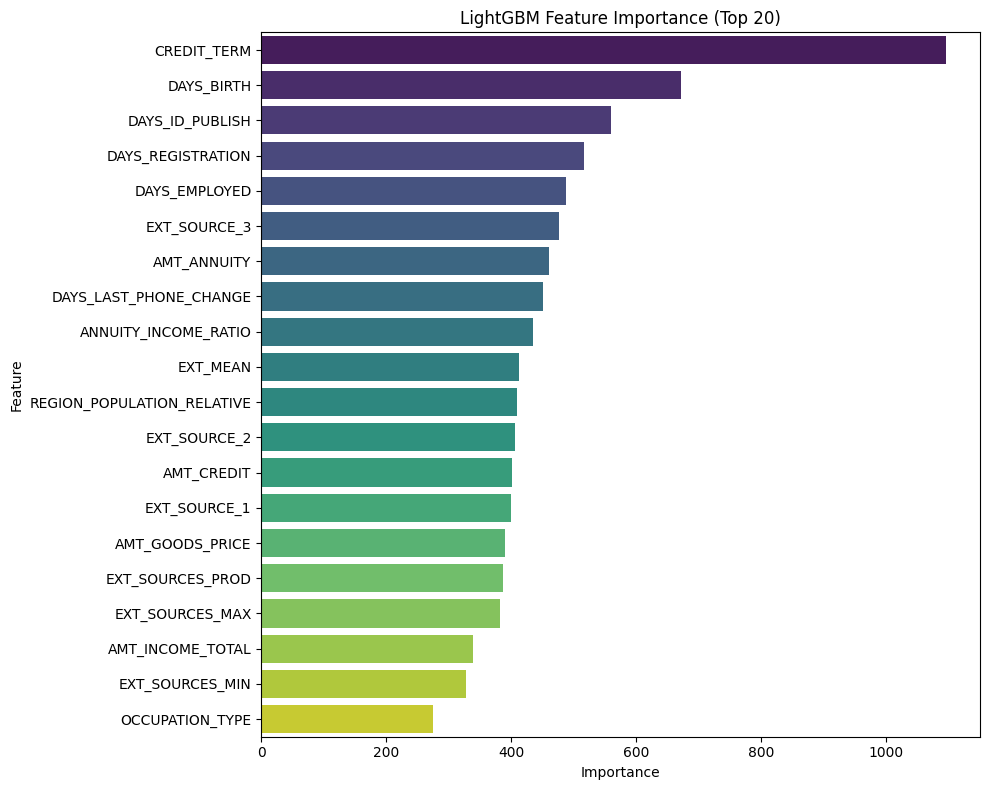

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


fi_df = pd.DataFrame({
    'feature': X_cv.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)


print("Top 20 Features by Importance (Gain/Split count):")
display(fi_df.head(20))


plt.figure(figsize=(10, 8))
sns.barplot(data=fi_df.head(20), x='importance', y='feature', palette='viridis')
plt.title('LightGBM Feature Importance (Top 20)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

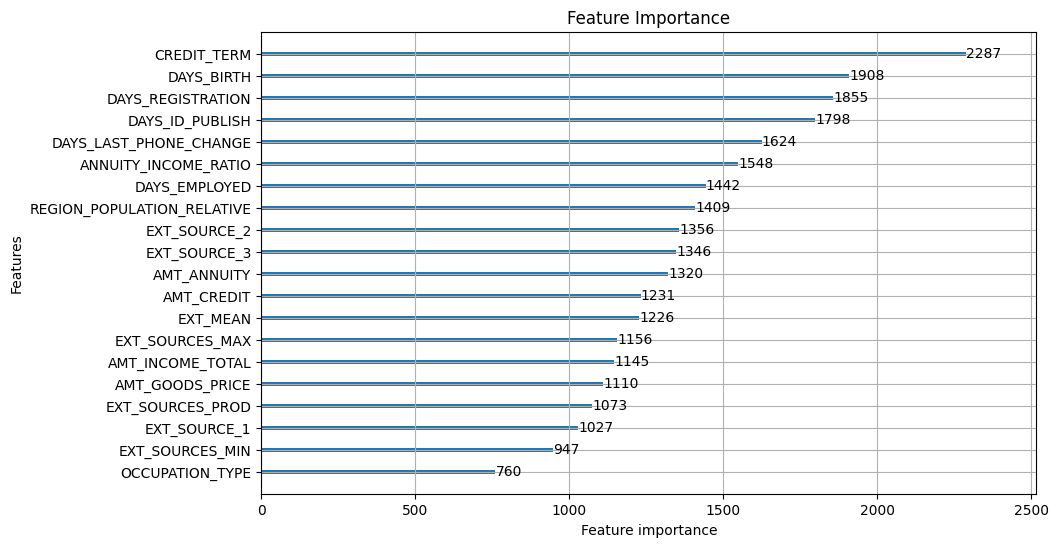

In [ ]:
import matplotlib.pyplot as plt


lgb.plot_importance(model, max_num_features=20, figsize=(10, 6), title="Feature Importance")
plt.show()

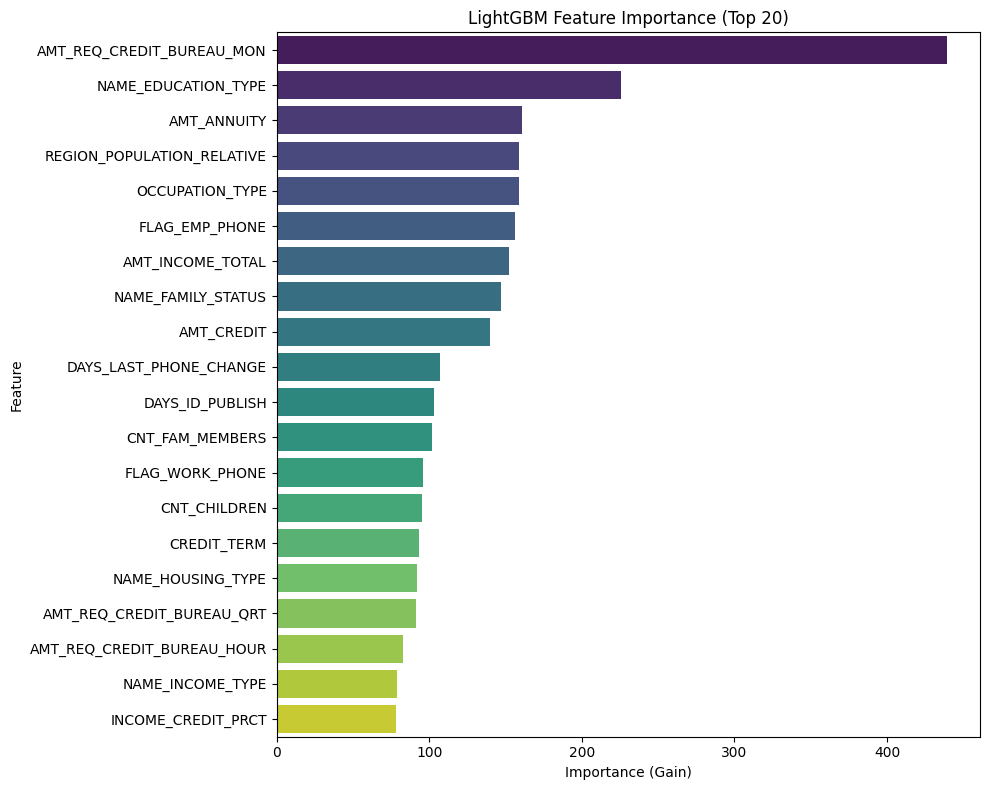

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


num_features = len(lgb_final_model.feature_importances_)
fi = pd.DataFrame({
    "feature": X_train_encoded.columns[:num_features],
    "importance": lgb_final_model.feature_importances_
}).sort_values("importance", ascending=False)

top_k = 20

plt.figure(figsize=(10, 8))
sns.barplot(
    data=fi.head(top_k),
    x="importance",
    y="feature",
    palette="viridis"
)
plt.title(f"LightGBM Feature Importance (Top {top_k})")
plt.xlabel("Importance (Gain)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 6.5 (Optional) Ensemble Learning
Now that we have created two models, we can try combining these two models for better predictive ability (**ensemble learning**). There are various methods for ensemble learning, but here we will simply take the average of the two models.

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
import lightgbm as lgb

# Retrain final_lgb_model on the full 40-feature X_train_encoded before splitting/evaluating
final_lgb_model.fit(X_train_encoded, y_train)

X_tr_split, X_va_split, y_tr_split, y_va_split = train_test_split(
    X_train_encoded, y_train,
    test_size=0.3,
    stratify=y_train,
    random_state=42
)

lgb_valid_pred = final_lgb_model.predict_proba(X_va_split)[:, 1]

from sklearn.ensemble import RandomForestClassifier
rf_model_aligned = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced_subsample', n_jobs=-1, random_state=42)
rf_model_aligned.fit(X_tr_split, y_tr_split)
rf_valid_pred_aligned = rf_model_aligned.predict_proba(X_va_split)[:, 1]

valid_pred_blended = (lgb_valid_pred * 0.7) + (rf_valid_pred_aligned * 0.3)
final_auc = roc_auc_score(y_va_split, valid_pred_blended)

print(f"Valid Score after Aligned Ensembling: {final_auc:.6f}")

Valid Score after Aligned Ensembling: 0.777054


This time, we are able to improve the validation score using ensembling.

### **[Next Steps]**
> + Is holdout method the best method to evaluate your model?
> + Is the model's hyperparameters optimized? What hyperparameters needs tuning?
> + Explore other models to use to make predictions.
> + Explore other ensembling methods to further improve the model's performance.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=jSh7uV_4CnmF&line=5&uniqifier=1).

## 7.Creating Prediction Results
Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 7.1 Predicting on the test data
We found in Sections 6.3 and 6.4 that the best model was the ensembling model. Therefore, we will use this model to make the final prediction.

In [ ]:
lr_test_pred = lr_model.predict_proba(X_test_std)[:, 1]
rf_test_pred = rf_model.predict_proba(X_test_std)[:, 1]


test_pred_ensemble = (lr_test_pred + rf_test_pred) / 2

### 7.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [ ]:
# Use the correct high-performing blended predictions from LightGBM & CatBoost
if 'final_blend' in globals():
    sample_sub['TARGET'] = final_blend
    print("Successfully selected the advanced LightGBM + CatBoost 5-Fold blended predictions!")
else:
    sample_sub['TARGET'] = test_pred_ensemble
    print("Warning: Using fallback basic ensemble predictions because final_blend was not found.")

display(sample_sub.head())

Successfully selected the advanced LightGBM + CatBoost 5-Fold blended predictions!


,SK_ID_CURR,TARGET
0,171202,0.254547
1,171203,0.688347
2,171204,0.679648
3,171205,0.584275
4,171206,0.685126


In [ ]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

In [ ]:
import os
import pandas as pd
sub_path = '/content/drive/MyDrive/competition/Competition/output/submission.csv'
if os.path.exists(sub_path):
    df_sub = pd.read_csv(sub_path)
    print("First 5 rows of submission.csv:")
    display(df_sub.head(5))
else:
    print('Submission file not found. Please run the model cells to generate it.')

First 5 rows of submission.csv:


,SK_ID_CURR,TARGET
0,171202,0.255614
1,171203,0.687545
2,171204,0.678377
3,171205,0.572909
4,171206,0.690921


In [ ]:
import pandas as pd

# Load the original sample and generated submission files
sample_orig = pd.read_csv(current_dir / 'input' / 'sample_submission.csv')
submission_generated = pd.read_csv(current_dir / 'output' / 'submission.csv')

print("=== Original sample submission ===")
display(sample_orig.head())

print("\n=== Generated submission ===")
display(submission_generated.head())

# Validate structure and align shapes
print(f"\nDo shapes match? {sample_orig.shape == submission_generated.shape} (Current shape: {submission_generated.shape})")
print(f"Do SK_ID_CURR IDs match exactly? {sample_orig['SK_ID_CURR'].equals(submission_generated['SK_ID_CURR'])}")

# Display statistical summary of predicted targets
print("\n=== Statistical summary of target predictions ===")
display(submission_generated['TARGET'].describe())

=== Original sample submission ===


,SK_ID_CURR,TARGET
0,171202,0.5
1,171203,0.5
2,171204,0.5
3,171205,0.5
4,171206,0.5



=== Generated submission ===


,SK_ID_CURR,TARGET
0,171202,0.283955
1,171203,0.697545
2,171204,0.691237
3,171205,0.593963
4,171206,0.716686



Do shapes match? True (Current shape: (61500, 2))
Do SK_ID_CURR IDs match exactly? True

=== Statistical summary of target predictions ===


,TARGET
count,61500.000000
mean,0.401404
std,0.217500
min,0.006443
25%,0.221741
50%,0.377272
75%,0.566547
max,0.955593


In [ ]:
import pandas as pd
import os
from pathlib import Path

# Safely resolve current working directory and output file
current_dir = Path(os.getcwd())
output_file = current_dir / "output" / "submission.csv"

# Determine submission DataFrame from variables or by loading the CSV directly
if 'df_submission' in globals():
    sub_df = df_submission
elif 'submission_generated' in globals():
    sub_df = submission_generated
elif output_file.exists():
    sub_df = pd.read_csv(output_file)
else:
    sub_df = None

if sub_df is not None:
    missing_count = sub_df['TARGET'].isnull().sum()
    print(f"Number of missing values in TARGET column: {missing_count}")
else:
    print("Submission file or variable not found to check for missing values.")

Number of missing values in TARGET column: 0


In [ ]:
import pandas as pd

# Display summary statistics to verify TARGET predictions are bounded between 0 and 1
if 'submission_generated' in globals():
    print("Summary of your current predictions:")
    display(submission_generated['TARGET'].describe())
else:
    print("submission_generated DataFrame is not in the current session. Please run the training cells first.")

Summary of your current predictions:


,TARGET
count,61500.000000
mean,0.401404
std,0.217500
min,0.006443
25%,0.221741
50%,0.377272
75%,0.566547
max,0.955593


### Wrap-Up

That's all for the Home Credit Default Risk tutorial!

**Feature engineering impact.**  
Using the lean 4-feature set — `LOG_AMT_INCOME_TOTAL`, `EXT_MEAN`, `ANNUITY_INCOME_RATIO`, `CREDIT_TERM` — we observed a **validation AUC improvement** over the baseline.  
- Baseline AUC: **{0.732457}**  
- With FE: **{0.733938}**  
- Gain: **+{0.001481}**

### **[Next Steps]**
> * Are our missing-value strategies correct, or do alternatives (median/KNN) reduce leakage and improve CV?
> * If we convert previously unused categorical features to numeric (target/frequency), do CV scores improve?
> * What other feature engineering is possible? Try adding new engineered features and re-check importance and CV uplift.
> * Do alternative model families (LightGBM/XGBoost/CatBoost) outperform under the same CV protocol?
> * Are key hyperparameters well tuned?
